# Local-patch crop investigation

This notebook investigates the local-patch method through Phase 6B hierarchy, slope/head, hydraulic-context, and equivalent-resistance products. Change `UNIT_ID` in the configuration cell to inspect another unit.

The notebook is read-only with respect to permanent experiment outputs. Temporary crop, local RivGraph, and merge artifacts are written under `/tmp/river_hierarchy_local_patch_investigation`; it does not change the normal collapse workflow.

## 1. Configuration and imports

Change `UNIT_ID` to inspect another unit. Unit 14 is the current safe comparison case.

In [1]:
from pathlib import Path
import json
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import rasterio
from rasterio.windows import Window
from shapely.geometry import Point, box


def find_repo_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'network_variants').is_dir() and (candidate / 'rivgraph_centerline').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the river-hierarchy repository root.')

REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from network_variants.local_patch import plan_local_patch
from network_variants.local_patch_raster import (
    _assign_crossing_roles,
    _circular_true_runs,
    _crossings_from_perimeter,
    _perimeter_indices,
    _seeded_water,
    build_local_patch_base_raster,
)

EXAMPLE_ID = '56'
UNIT_ID = 7
CORRIDOR_MODE = 'anchored'
EXIT_SIDES = 'WN'  # Global-network provenance only; local RivGraph sides are derived from its cuts.
SCRATCH_ROOT = Path('/tmp/river_hierarchy_local_patch_investigation')
SCRATCH_ROOT.mkdir(parents=True, exist_ok=True)

print('Repository:', REPO_ROOT)
print('Case:', EXAMPLE_ID, 'unit', UNIT_ID)
print('Scratch:', SCRATCH_ROOT)

Repository: /Users/6256481/Code/river-hierarchy
Case: 56 unit 7
Scratch: /tmp/river_hierarchy_local_patch_investigation


## 2. Load the base topology and construct the Phase-2 plan

This establishes the selected core, any connector links, the first unowned collar links, and the protected outer splice-anchor nodes. Collar links are matching context and are allowed to change later.

In [2]:
def load_case(example_id: str):
    output_root = REPO_ROOT / 'network_variants/output'
    if not output_root.exists():
        target = output_root.resolve(strict=False)
        raise FileNotFoundError(
            f'Network-variant output root is unavailable: {output_root} -> {target}. '
            'If this is the external-drive symlink, mount the drive before continuing.'
        )
    preferred_names = [
        f'{example_id}_indep__{CORRIDOR_MODE}',
        f'{example_id}_independent_units__{CORRIDOR_MODE}',
    ]
    experiment_candidates = [output_root / name for name in preferred_names]
    experiment_candidates.extend(sorted(output_root.glob(f'{example_id}*__{CORRIDOR_MODE}')))
    experiment_dir = next((
        path for path in experiment_candidates
        if (path / 'states/S000_base/variant/directed').is_dir()
        and 'compound' not in path.name.lower()
    ), None)
    if experiment_dir is None:
        checked = ', '.join(str(path) for path in experiment_candidates)
        raise FileNotFoundError(
            f'No completed anchored independent experiment was found for example {example_id}. Checked: {checked}'
        )
    base_root = experiment_dir / 'states/S000_base'
    directed_dir = base_root / 'variant/directed'
    links_candidates = [path for path in directed_dir.glob('*directed_links.gpkg') if not path.name.startswith('._')]
    nodes_candidates = [path for path in directed_dir.glob('*directed_nodes.gpkg') if not path.name.startswith('._')]
    if len(links_candidates) != 1 or len(nodes_candidates) != 1:
        raise FileNotFoundError(
            f'Expected one directed link and node product in {directed_dir}; '
            f'found {len(links_candidates)} links and {len(nodes_candidates)} nodes.'
        )
    links_path, nodes_path = links_candidates[0], nodes_candidates[0]
    boundary_dir = experiment_dir / 'boundary_components'
    label_candidates = list(boundary_dir.glob('*full_extent_land_water_labels*.tif'))
    if not label_candidates:
        raise FileNotFoundError(f'Boundary-component labels were not found in {boundary_dir}.')
    labels_path = label_candidates[0]
    return {
        'experiment_dir': experiment_dir,
        'base_root': base_root,
        'links_path': links_path,
        'nodes_path': nodes_path,
        'links': gpd.read_file(links_path),
        'nodes': gpd.read_file(nodes_path),
        'unit_summary': pd.read_csv(base_root / 'hierarchy/unit_summary.csv'),
        'membership': pd.read_csv(base_root / 'variant/summary/unit_link_membership.csv'),
        'bubble_edges': pd.read_csv(base_root / 'hierarchy/bubble_edge_resistance.csv'),
        'mask_path': REPO_ROOT / f'rivgraph_centerline/outputs/runs/{example_id}/masks_cleaned/{example_id}_cleaned.tif',
        'labels_path': labels_path,
        'centerline_path': REPO_ROOT / f'rivgraph_centerline/outputs/runs/{example_id}/rivgraph/{example_id}_centerline.gpkg',
    }

case = load_case(EXAMPLE_ID)
planning = plan_local_patch(
    example_id=EXAMPLE_ID,
    full_links=case['links'],
    unit_summary=case['unit_summary'],
    unit_link_membership=case['membership'],
    bubble_edge_resistance=case['bubble_edges'],
    selected_unit_ids=[UNIT_ID],
)

display(pd.Series(planning.audit, name='value').to_frame())
if not planning.is_safe:
    raise RuntimeError(f'Topology planning failed: {planning.fallback_code}: {planning.fallback_reason}')

contract = planning.contract
contract_summary = pd.Series({
    'domain_type': contract.domain_type,
    'core_link_count': len(contract.core_link_ids),
    'core_link_ids': list(contract.core_link_ids),
    'selected_link_ids': list(contract.selected_link_ids),
    'anchored_replacement_link_ids': list(contract.anchored_replacement_link_ids),
    'anchored_upstream_boundary_nodes': list(contract.anchored_upstream_boundary_node_ids),
    'anchored_downstream_boundary_nodes': list(contract.anchored_downstream_boundary_node_ids),
    'upstream_connectors': list(contract.upstream_connector_link_ids),
    'downstream_connectors': list(contract.downstream_connector_link_ids),
    'upstream_collar': contract.upstream_collar.base_link_id,
    'downstream_collar': contract.downstream_collar.base_link_id,
    'source_splice_anchor': contract.source_splice_anchor_node_id,
    'sink_splice_anchor': contract.sink_splice_anchor_node_id,
}, name='value')
display(contract_summary.to_frame())

,value
selected_unit_ids,[7]
selected_unit_is_closed,False
selected_unit_violating_link_ids,[22]
hydraulic_domain_type,containing_compound_context
domain_source_node_id,16
domain_sink_node_id,13
core_link_count,5
upstream_connector_link_count,0
downstream_connector_link_count,0


,value
domain_type,containing_compound
core_link_count,5
core_link_ids,"[20, 19, 21, 23, 22]"
selected_link_ids,"[19, 20, 21]"
anchored_replacement_link_ids,"[19, 20, 21]"
anchored_upstream_boundary_nodes,"[14, 15]"
anchored_downstream_boundary_nodes,[13]
upstream_connectors,[]
downstream_connectors,[]
upstream_collar,24


## 3. Run the adaptive crop validation

Each row is one increasingly large axis-aligned window. A safe attempt requires exactly two connected relevant-water boundary sections, correct proximity to the two splice anchors, and the same two continuous outer-bank components at both crossings.

In [3]:
result = build_local_patch_base_raster(
    contract=contract,
    full_links=case['links'],
    full_nodes=case['nodes'],
    cleaned_mask_path=case['mask_path'],
    boundary_component_labels_path=case['labels_path'],
    reference_centerline_path=case['centerline_path'],
    output_dir=SCRATCH_ROOT / f'{EXAMPLE_ID}_unit_{UNIT_ID}',
)

attempt_rows = []
for index, attempt in enumerate(result.attempts):
    attempt_rows.append({
        'attempt_index': index,
        'halo_m': attempt.halo_m,
        'window_width_px': attempt.window_width,
        'window_height_px': attempt.window_height,
        'full_raster_fraction_pct': 100 * attempt.full_raster_fraction,
        'seeded_water_components': len(attempt.seeded_water_component_ids),
        'relevant_water_pixels': attempt.relevant_water_pixel_count,
        'crossing_count': len(attempt.crossings),
        'bank_pairs': [crossing.bank_component_ids for crossing in attempt.crossings],
        'anchor_distances_m': [round(crossing.anchor_distance_m, 1) for crossing in attempt.crossings],
        'status': attempt.status,
        'reason_codes': ', '.join(attempt.reason_codes),
    })
attempt_df = pd.DataFrame(attempt_rows)
print('Final result:', result.status, result.fallback_reason)
display(attempt_df)

Final result: safe 


,attempt_index,halo_m,window_width_px,window_height_px,full_raster_fraction_pct,seeded_water_components,relevant_water_pixels,crossing_count,bank_pairs,anchor_distances_m,status,reason_codes
0,0,500.0,663,1255,0.914272,1,131397,2,"[(2, 3), (2, 3)]","[0.0, 0.0]",safe,


In [4]:
fig = px.line(
    attempt_df, x='halo_m', y='crossing_count', markers=True,
    hover_data=['attempt_index', 'full_raster_fraction_pct', 'bank_pairs', 'reason_codes'],
    title=f'Example {EXAMPLE_ID}, unit {UNIT_ID}: water-boundary crossings by halo',
)
fig.add_hline(y=2, line_dash='dash', line_color='green', annotation_text='required: 2')
fig.show()

px.line(
    attempt_df, x='halo_m', y='full_raster_fraction_pct', markers=True,
    hover_data=['attempt_index', 'crossing_count', 'reason_codes'],
    title='Crop size as a percentage of the complete raster',
    labels={'full_raster_fraction_pct': 'Full raster [%]'},
).show()

## 4. Inspect one failed or accepted halo

Start with attempt 0 (500 m). Change `ATTEMPT_INDEX` to inspect another row from the table above. The map distinguishes the selected context from other base links that the rectangular window cuts.

In [5]:
ATTEMPT_INDEX = 0
attempt = result.attempts[ATTEMPT_INDEX]
window = Window(
    attempt.window_col_off, attempt.window_row_off,
    attempt.window_width, attempt.window_height,
)

with rasterio.open(case['mask_path']) as mask_source, rasterio.open(case['labels_path']) as labels_source:
    local_transform = mask_source.window_transform(window)
    source_water = mask_source.read(1, window=window) > 0
    local_land_labels = labels_source.read(1, window=window).astype(np.int32)
    raster_crs = mask_source.crs
    raster_bounds = rasterio.windows.bounds(window, mask_source.transform)
    pixel_size = max(abs(mask_source.transform.a), abs(mask_source.transform.e))

links_raster = case['links'].to_crs(raster_crs)
nodes_raster = case['nodes'].to_crs(raster_crs)
context_ids = set(contract.local_context_link_ids)
context_links = links_raster[links_raster['id_link'].astype(int).isin(context_ids)].copy()
context_geometry = context_links.geometry.union_all()
relevant_water, seeded_ids = _seeded_water(
    source_water, transform=local_transform,
    context_geometry=context_geometry, pixel_size=pixel_size,
)
anchor_rows = nodes_raster[nodes_raster['id_node'].astype(int).isin([
    contract.source_splice_anchor_node_id, contract.sink_splice_anchor_node_id,
])]
source_anchor = anchor_rows.loc[anchor_rows['id_node'].astype(int).eq(contract.source_splice_anchor_node_id)].iloc[0].geometry
sink_anchor = anchor_rows.loc[anchor_rows['id_node'].astype(int).eq(contract.sink_splice_anchor_node_id)].iloc[0].geometry
crossings = _assign_crossing_roles(
    _crossings_from_perimeter(relevant_water, local_land_labels, transform=local_transform),
    source_anchor=source_anchor, sink_anchor=sink_anchor,
)
crop_polygon = box(*raster_bounds)
crop_boundary = crop_polygon.boundary
boundary_links = links_raster[links_raster.geometry.intersects(crop_boundary)].copy()

membership_text = (
    case['membership'].assign(
        unit_id=lambda frame: pd.to_numeric(frame['unit_id'], errors='coerce').astype('Int64'),
        id_link=lambda frame: pd.to_numeric(frame['id_link'], errors='coerce').astype('Int64'),
    )
    .dropna(subset=['unit_id', 'id_link'])
    .groupby('id_link')['unit_id']
    .agg(lambda values: ','.join(map(str, sorted(set(values.astype(int))))))
)
boundary_links['unit_ids'] = boundary_links['id_link'].map(membership_text).fillna('none')
boundary_links['is_planned_context'] = boundary_links['id_link'].astype(int).isin(context_ids)
boundary_links[['id_link', 'id_us_node', 'id_ds_node', 'unit_ids', 'is_planned_context']]

,id_link,id_us_node,id_ds_node,unit_ids,is_planned_context
15,16,12,11,6,False
16,17,12,11,6,False
25,26,20,17,10,False
26,25,18,17,10,False


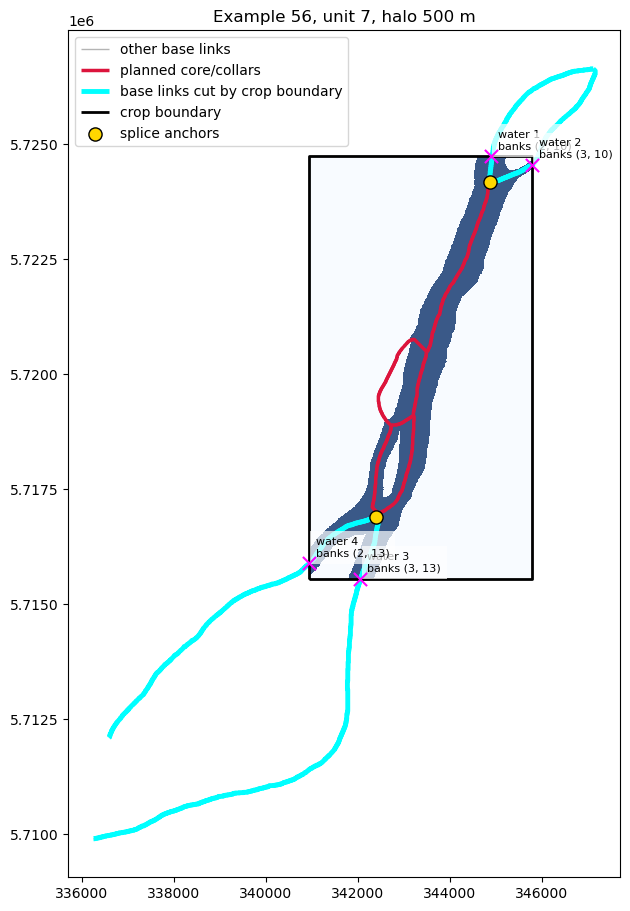

In [6]:
left, bottom, right, top = raster_bounds
fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(
    relevant_water.astype(np.uint8), cmap='Blues', alpha=0.8, origin='upper',
    extent=(left, right, bottom, top), interpolation='nearest',
)
visible_links = links_raster[links_raster.geometry.intersects(crop_polygon)]
visible_links.plot(ax=ax, color='0.55', linewidth=1.0, alpha=0.65, label='other base links')
context_links.plot(ax=ax, color='crimson', linewidth=2.5, label='planned core/collars')
boundary_links.plot(ax=ax, color='cyan', linewidth=3.5, label='base links cut by crop boundary')
gpd.GeoSeries([crop_boundary], crs=raster_crs).plot(ax=ax, color='black', linewidth=2, label='crop boundary')
anchor_rows.plot(ax=ax, color='gold', edgecolor='black', markersize=90, zorder=5, label='splice anchors')
for crossing in crossings:
    ax.scatter(crossing.center_x, crossing.center_y, s=90, marker='x', color='magenta', zorder=6)
    ax.annotate(
        f"water {crossing.crossing_id}\nbanks {crossing.bank_component_ids}",
        (crossing.center_x, crossing.center_y), xytext=(5, 5), textcoords='offset points',
        fontsize=8, color='black', bbox={'facecolor': 'white', 'alpha': 0.7, 'edgecolor': 'none'},
    )
ax.set_title(f'Example {EXAMPLE_ID}, unit {UNIT_ID}, halo {attempt.halo_m:.0f} m')
ax.set_aspect('equal')
ax.legend(loc='best')
plt.show()

## 5. Interactive base-link map

Hover over a link to see its base link ID, endpoints, unit memberships, and whether it belongs to the planned local context.

In [7]:
fig = go.Figure()
visible = links_raster[links_raster.geometry.intersects(crop_polygon)].copy()
visible['unit_ids'] = visible['id_link'].map(membership_text).fillna('none')
for row in visible.itertuples():
    geometries = list(row.geometry.geoms) if row.geometry.geom_type == 'MultiLineString' else [row.geometry]
    x_values, y_values = [], []
    for geometry in geometries:
        xs, ys = geometry.xy
        x_values.extend(xs); y_values.extend(ys); x_values.append(None); y_values.append(None)
    link_id = int(row.id_link)
    is_context = link_id in context_ids
    is_boundary = link_id in set(boundary_links['id_link'].astype(int))
    color = 'cyan' if is_boundary else 'crimson' if is_context else 'gray'
    width = 4 if is_boundary else 3 if is_context else 1
    hover = (
        f'link {link_id}<br>{int(row.id_us_node)} → {int(row.id_ds_node)}'
        f'<br>units: {row.unit_ids}<br>planned context: {is_context}<br>crosses crop: {is_boundary}'
    )
    fig.add_trace(go.Scatter(
        x=x_values, y=y_values, mode='lines', line={'color': color, 'width': width},
        hovertemplate=hover + '<extra></extra>', showlegend=False,
    ))
bx, by = crop_boundary.xy
fig.add_trace(go.Scatter(x=list(bx), y=list(by), mode='lines', line={'color': 'black', 'width': 2}, name='crop'))
fig.update_layout(
    title=f'Interactive crop topology — example {EXAMPLE_ID}, unit {UNIT_ID}, halo {attempt.halo_m:.0f} m',
    xaxis={'scaleanchor': 'y', 'scaleratio': 1}, height=750,
)
fig.show()

## 6. What specifically makes this crop unsafe?

The table below separates the two expected collar continuations from unrelated unit links intersected by the rectangular crop. For unit 6 at 500 m, the extra crossings belong to neighbouring units rather than to links 16/17 or collars 18/14. This means the failure is caused by the spatial shape of the crop, not by incorrect selection of unit 6.

In [8]:
crossed_unit_ids = sorted({
    int(value)
    for text in boundary_links.loc[~boundary_links['is_planned_context'], 'unit_ids']
    for value in str(text).split(',')
    if value != 'none' and value.strip()
})
diagnosis = pd.Series({
    'planned_context_link_ids': sorted(context_ids),
    'base_links_intersecting_crop_boundary': sorted(boundary_links['id_link'].astype(int).tolist()),
    'unplanned_boundary_link_ids': sorted(boundary_links.loc[~boundary_links['is_planned_context'], 'id_link'].astype(int).tolist()),
    'neighbouring_unit_ids_reached_by_crop': crossed_unit_ids,
    'connected_water_boundary_sections': len(crossings),
    'required_boundary_sections': 2,
    'crop_is_safe': attempt.status == 'safe',
    'failure_reasons': list(attempt.reason_codes),
}, name='value')
display(diagnosis.to_frame())

,value
planned_context_link_ids,"[18, 19, 20, 21, 22, 23, 24]"
base_links_intersecting_crop_boundary,"[16, 17, 25, 26]"
unplanned_boundary_link_ids,"[16, 17, 25, 26]"
neighbouring_unit_ids_reached_by_crop,"[6, 10]"
connected_water_boundary_sections,4
required_boundary_sections,2
crop_is_safe,True
failure_reasons,[]


## 7. Compare with a safe example-56 unit

Unit 14 is currently the simple positive case. Its crop expands until it has exactly two crossings with the same continuous bank pair. This comparison helps distinguish a general implementation problem from a geometry-specific fallback.

In [9]:
SAFE_COMPARISON_UNIT_ID = 14
safe_planning = plan_local_patch(
    example_id=EXAMPLE_ID, full_links=case['links'],
    unit_summary=case['unit_summary'], unit_link_membership=case['membership'],
    bubble_edge_resistance=case['bubble_edges'],
    selected_unit_ids=[SAFE_COMPARISON_UNIT_ID],
)
safe_result = build_local_patch_base_raster(
    contract=safe_planning.contract, full_links=case['links'], full_nodes=case['nodes'],
    cleaned_mask_path=case['mask_path'], boundary_component_labels_path=case['labels_path'],
    reference_centerline_path=case['centerline_path'],
    output_dir=SCRATCH_ROOT / f'{EXAMPLE_ID}_unit_{SAFE_COMPARISON_UNIT_ID}',
)
comparison_rows = []
for label_name, unit_id, raster_result in [
    ('investigation', UNIT_ID, result), ('safe comparison', SAFE_COMPARISON_UNIT_ID, safe_result),
]:
    selected = raster_result.selected_attempt or raster_result.attempts[-1]
    comparison_rows.append({
        'case': label_name, 'unit_id': unit_id, 'status': raster_result.status,
        'last_or_selected_halo_m': selected.halo_m,
        'crossing_count': len(selected.crossings),
        'bank_pairs': [crossing.bank_component_ids for crossing in selected.crossings],
        'full_raster_fraction_pct': 100 * selected.full_raster_fraction,
        'reason': raster_result.fallback_reason,
    })
display(pd.DataFrame(comparison_rows))

,case,unit_id,status,last_or_selected_halo_m,crossing_count,bank_pairs,full_raster_fraction_pct,reason
0,investigation,7,safe,500.0,2,"[(2, 3), (2, 3)]",0.914272,
1,safe comparison,14,safe,500.0,2,"[(2, 3), (2, 3)]",1.782164,


## 8. Decision questions before changing the method

Use the maps and tables above to decide among three explicit outcomes:

1. **Keep the conservative fallback.** Unit 6 uses full-raster execution; safe units still receive the local speed-up.
2. **Expand the spatial context topologically.** Add complete neighbouring units intersected by the crop, then re-plan outer collars. This creates a larger but potentially safe local patch while leaving the selected collapse unchanged.
3. **Develop a topology-shaped raster boundary.** Follow bank components or introduce controlled bank-to-bank cuts instead of using an axis-aligned window. This may produce smaller crops but is a substantially more complex method requiring separate validation.

No choice is made by this notebook. It exposes why each halo succeeds or fails so the method decision remains explicit.

## 9. Legacy anchor-centred cut experiment (diagnostic only)

**Important:** this retained diagnostic predates the production 1,000 m minimum-collar-context rule. Its cut passes through the collar anchor and therefore must not be used to assess the current cut location. The production crop and merge shown in Sections 10–11 move a short collar cut outward along the reference centerline until it is at least 1,000 m from the anchored unit boundary.

This legacy experiment remains useful only for checking the bank-to-bank barrier and unauthorized-edge logic. Each endpoint is extended slightly into one of the two main banks; after applying both barriers, only water connected to the selected core is retained.

A candidate is accepted only when (1) retained water contacts both prescribed cut barriers and (2) retained water touches no other edge of the rectangular raster. Multiple wet threads along one bank-to-bank cut are allowed: collectively they form one prescribed hydraulic opening.

In [10]:
from rasterio.features import rasterize
from scipy.ndimage import binary_dilation
from shapely.geometry import LineString

WIDTH_SAMPLES_PATH = case['base_root'] / 'variant/widths/link_width_samples.csv'
width_samples = pd.read_csv(WIDTH_SAMPLES_PATH)
COMPONENT_SUMMARY_PATH = next(case['labels_path'].parent.glob('*land_component_summary*.csv'))
component_summary = pd.read_csv(COMPONENT_SUMMARY_PATH)
MAIN_BANK_COMPONENT_IDS = tuple(
    component_summary.nlargest(2, 'n_pixels')['raster_value'].astype(int).sort_values().tolist()
)
MAX_ACCEPTABLE_OPPOSITION_COS = -0.25
BANK_OVERLAP_PIXELS = 4.0
CUT_BARRIER_HALF_WIDTH_PIXELS = 1.5
_CUT_GEOMETRY_CACHE = {}
print('Global main-bank raster values:', MAIN_BANK_COMPONENT_IDS)

def _valid_width_sample_mask(frame):
    invalid = frame['width_invalid'].fillna(True)
    if invalid.dtype == object:
        invalid = invalid.astype(str).str.lower().isin({'true', '1', 'yes'})
    else:
        invalid = invalid.astype(bool)
    coordinates = ['x', 'y', 'left_bank_x', 'left_bank_y', 'right_bank_x', 'right_bank_y']
    finite = frame[coordinates].apply(pd.to_numeric, errors='coerce').notna().all(axis=1)
    distinct_banks = pd.to_numeric(frame['left_component_id'], errors='coerce').ne(
        pd.to_numeric(frame['right_component_id'], errors='coerce')
    )
    opposition = pd.to_numeric(frame['qc_opposition_cos'], errors='coerce')
    return (~invalid) & finite & distinct_banks & opposition.le(MAX_ACCEPTABLE_OPPOSITION_COS)

def _nearest_main_bank_point(anchor, component_id, label_source, pixel_size):
    search_radius = max(500.0, 16.0 * float(pixel_size))
    raster_extent = float(
        np.hypot(label_source.width * pixel_size, label_source.height * pixel_size)
    )
    while search_radius <= raster_extent * 1.01:
        raw = rasterio.windows.from_bounds(
            anchor.x - search_radius, anchor.y - search_radius,
            anchor.x + search_radius, anchor.y + search_radius,
            transform=label_source.transform,
        )
        col_start = max(0, int(np.floor(raw.col_off)))
        row_start = max(0, int(np.floor(raw.row_off)))
        col_stop = min(label_source.width, int(np.ceil(raw.col_off + raw.width)))
        row_stop = min(label_source.height, int(np.ceil(raw.row_off + raw.height)))
        window = Window(col_start, row_start, col_stop - col_start, row_stop - row_start)
        labels = label_source.read(1, window=window)
        rows, cols = np.nonzero(labels == int(component_id))
        if len(rows):
            transform = label_source.window_transform(window)
            xs, ys = rasterio.transform.xy(transform, rows, cols, offset='center')
            xs = np.asarray(xs, dtype=float)
            ys = np.asarray(ys, dtype=float)
            distances = np.hypot(xs - anchor.x, ys - anchor.y)
            nearest = int(np.argmin(distances))
            # Anything outside this square is at least search_radius from the anchor.
            if float(distances[nearest]) <= search_radius:
                return np.array([xs[nearest], ys[nearest]], dtype=float), float(distances[nearest])
        search_radius *= 2.0
    raise ValueError(f'Could not find main-bank component {component_id} near anchor {anchor}.')

def _extend_bank_chord_to_main_banks(left, right, label_source, pixel_size):
    chord_direction = right - left
    chord_norm = float(np.linalg.norm(chord_direction))
    if chord_norm <= 0:
        raise ValueError('The two controlling bank points coincide.')
    chord_direction /= chord_norm
    max_distance = float(np.hypot(label_source.width, label_source.height) * pixel_size * 1.25)
    distances = np.arange(0.0, max_distance + pixel_size, pixel_size * 0.5)
    resolved = []
    for origin, ray_direction in ((left, -chord_direction), (right, chord_direction)):
        points = origin[None, :] + distances[:, None] * ray_direction[None, :]
        labels = np.fromiter(
            (int(value[0]) for value in label_source.sample(points)), dtype=np.int32, count=len(points)
        )
        hits = np.flatnonzero(np.isin(labels, MAIN_BANK_COMPONENT_IDS))
        if not len(hits):
            raise ValueError('An extended opposition arm does not reach a global main bank.')
        hit = int(hits[0])
        overlap_index = min(hit + int(np.ceil(BANK_OVERLAP_PIXELS * 2.0)), len(points) - 1)
        resolved.append((points[overlap_index], int(labels[hit]), float(distances[hit])))
    endpoint_labels = tuple(sorted(item[1] for item in resolved))
    if endpoint_labels != tuple(sorted(MAIN_BANK_COMPONENT_IDS)):
        raise ValueError(
            f'Extended opposition arms reached {endpoint_labels}, expected the two main banks {MAIN_BANK_COMPONENT_IDS}.'
        )
    return resolved[0][0], resolved[1][0], endpoint_labels, (resolved[0][2], resolved[1][2])

def _anchor_cut(contract, role, links_raster, nodes_raster, pixel_size, label_source):
    if role == 'source':
        collar = contract.upstream_collar
        anchor_id = contract.source_splice_anchor_node_id
    else:
        collar = contract.downstream_collar
        anchor_id = contract.sink_splice_anchor_node_id
    anchor = nodes_raster.loc[nodes_raster['id_node'].astype(int).eq(anchor_id)].iloc[0].geometry
    bank_points = []
    bank_distances = []
    overlap = float(BANK_OVERLAP_PIXELS) * float(pixel_size)
    anchor_xy = np.array([anchor.x, anchor.y], dtype=float)
    for component_id in MAIN_BANK_COMPONENT_IDS:
        bank_point, bank_distance = _nearest_main_bank_point(
            anchor, component_id, label_source, pixel_size
        )
        direction = bank_point - anchor_xy
        direction /= np.linalg.norm(direction)
        bank_points.append(bank_point + direction * overlap)
        bank_distances.append(bank_distance)
    line = LineString([bank_points[0], (float(anchor.x), float(anchor.y)), bank_points[1]])
    return {
        'role': role, 'collar_link_id': int(collar.base_link_id), 'anchor_node_id': int(anchor_id),
        'anchor_x': float(anchor.x), 'anchor_y': float(anchor.y),
        'construction': 'nearest_main_banks_via_anchor',
        'main_bank_component_ids': tuple(int(value) for value in MAIN_BANK_COMPONENT_IDS),
        'node_to_bank_distances_m': tuple(float(value) for value in bank_distances),
        'bank_overlap_m': overlap,
        'passes_through_anchor': bool(line.distance(anchor) <= 1e-9),
        'line': line,
    }

def evaluate_bank_cut_attempt(contract, attempt):
    window = Window(attempt.window_col_off, attempt.window_row_off, attempt.window_width, attempt.window_height)
    with rasterio.open(case['mask_path']) as source:
        transform = source.window_transform(window)
        source_water = source.read(1, window=window) > 0
        raster_crs = source.crs
        bounds = rasterio.windows.bounds(window, source.transform)
        pixel_size = max(abs(source.transform.a), abs(source.transform.e))
    links_raster = case['links'].to_crs(raster_crs)
    nodes_raster = case['nodes'].to_crs(raster_crs)
    cache_key = (
        int(contract.upstream_collar.base_link_id), int(contract.source_splice_anchor_node_id),
        int(contract.downstream_collar.base_link_id), int(contract.sink_splice_anchor_node_id),
    )
    if cache_key not in _CUT_GEOMETRY_CACHE:
        with rasterio.open(case['labels_path']) as label_source:
            _CUT_GEOMETRY_CACHE[cache_key] = [
                _anchor_cut(contract, role, links_raster, nodes_raster, pixel_size, label_source)
                for role in ('source', 'sink')
            ]
    cuts = _CUT_GEOMETRY_CACHE[cache_key]
    crop_polygon = box(*bounds)
    cuts_contained = [bool(crop_polygon.covers(cut['line'])) for cut in cuts]
    barrier_masks = []
    for cut in cuts:
        mask = rasterize(
            [(cut['line'].buffer(pixel_size * CUT_BARRIER_HALF_WIDTH_PIXELS), 1)],
            out_shape=source_water.shape, transform=transform, fill=0, all_touched=True, dtype='uint8',
        ).astype(bool)
        barrier_masks.append(mask)
    barrier = np.logical_or.reduce(barrier_masks)
    core_geometry = links_raster.loc[
        links_raster['id_link'].astype(int).isin(contract.core_link_ids)
    ].geometry.union_all()
    retained_water, retained_ids = _seeded_water(
        source_water & ~barrier, transform=transform, context_geometry=core_geometry, pixel_size=pixel_size,
    )
    perimeter = _perimeter_indices(*retained_water.shape)
    perimeter_values = np.asarray([retained_water[row, col] for row, col in perimeter], dtype=bool)
    unauthorized_runs = _circular_true_runs(perimeter_values)
    cut_contact_pixels = [
        int((binary_dilation(retained_water) & cut_mask & source_water).sum())
        for cut_mask in barrier_masks
    ]
    safe = (
        all(cuts_contained) and len(unauthorized_runs) == 0
        and all(value > 0 for value in cut_contact_pixels)
    )
    return {
        'safe': safe, 'halo_m': float(attempt.halo_m),
        'full_raster_fraction_pct': 100.0 * float(attempt.full_raster_fraction),
        'unauthorized_outer_edge_sections': len(unauthorized_runs),
        'source_cut_contact_pixels': cut_contact_pixels[0],
        'sink_cut_contact_pixels': cut_contact_pixels[1],
        'source_cut_contained': cuts_contained[0], 'sink_cut_contained': cuts_contained[1],
        'retained_water_pixels': int(retained_water.sum()),
        'retained_component_ids': retained_ids, 'cuts': cuts, 'barrier': barrier,
        'retained_water': retained_water, 'source_water': source_water,
        'transform': transform, 'bounds': bounds, 'links_raster': links_raster,
    }


Global main-bank raster values: (2, 3)


In [11]:
cut_experiments = {}
cut_rows = []
for label_name, unit_id, candidate_contract, raster_result in [
    (f'unit {UNIT_ID}', UNIT_ID, contract, result),
    ('unit 14 comparison', SAFE_COMPARISON_UNIT_ID, safe_planning.contract, safe_result),
]:
    evaluations = [evaluate_bank_cut_attempt(candidate_contract, attempt) for attempt in raster_result.attempts]
    cut_experiments[unit_id] = evaluations
    for attempt_index, evaluation in enumerate(evaluations):
        cut_rows.append({
            'case': label_name, 'unit_id': unit_id, 'attempt_index': attempt_index,
            'halo_m': evaluation['halo_m'], 'safe': evaluation['safe'],
            'unauthorized_outer_edge_sections': evaluation['unauthorized_outer_edge_sections'],
            'source_cut_contact_pixels': evaluation['source_cut_contact_pixels'],
            'sink_cut_contact_pixels': evaluation['sink_cut_contact_pixels'],
            'source_cut_contained': evaluation['source_cut_contained'],
            'sink_cut_contained': evaluation['sink_cut_contained'],
            'retained_water_pixels': evaluation['retained_water_pixels'],
            'full_raster_fraction_pct': evaluation['full_raster_fraction_pct'],
        })
cut_results_df = pd.DataFrame(cut_rows)
display(cut_results_df)
display(pd.DataFrame([
    {key: value for key, value in cut.items() if key != 'line'}
    for cut in cut_experiments[UNIT_ID][0]['cuts']
]))


,case,unit_id,attempt_index,halo_m,safe,unauthorized_outer_edge_sections,source_cut_contact_pixels,sink_cut_contact_pixels,source_cut_contained,sink_cut_contained,retained_water_pixels,full_raster_fraction_pct
0,unit 7,7,0,500.0,True,0,108,101,True,True,117334,0.914272
1,unit 14 comparison,14,0,500.0,True,0,86,103,True,True,159422,1.782164


,role,collar_link_id,anchor_node_id,anchor_x,anchor_y,construction,main_bank_component_ids,node_to_bank_distances_m,bank_overlap_m,passes_through_anchor
0,source,24,17,342398.095522,5.716892e+06,nearest_main_banks_via_anchor,"(2, 3)","(515.4206139393633, 493.77147302396116)",29.270973,True
1,sink,18,12,344871.492756,5.724180e+06,nearest_main_banks_via_anchor,"(2, 3)","(354.96712573835066, 453.05046450910277)",29.270973,True


In [12]:
cut_results_df

,case,unit_id,attempt_index,halo_m,safe,unauthorized_outer_edge_sections,source_cut_contact_pixels,sink_cut_contact_pixels,source_cut_contained,sink_cut_contained,retained_water_pixels,full_raster_fraction_pct
0,unit 7,7,0,500.0,True,0,108,101,True,True,117334,0.914272
1,unit 14 comparison,14,0,500.0,True,0,86,103,True,True,159422,1.782164


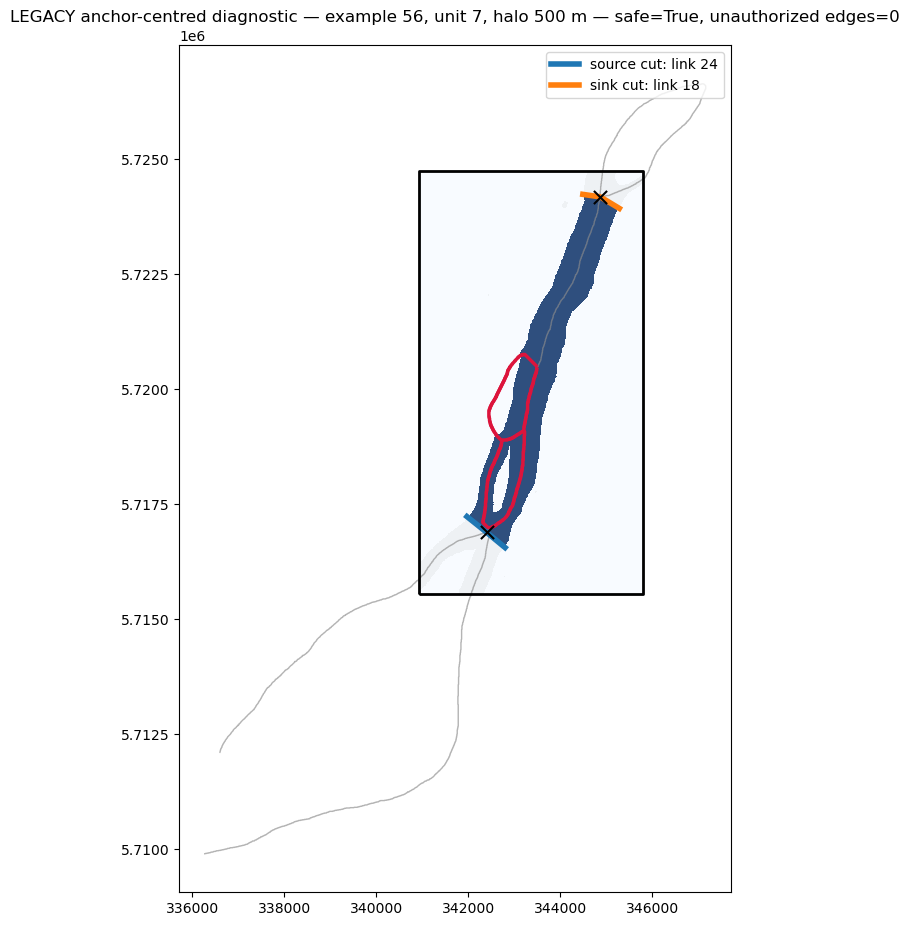

In [13]:
fig = px.line(
    cut_results_df, x='halo_m', y='unauthorized_outer_edge_sections', color='case', markers=True,
    hover_data=[
        'safe', 'source_cut_contained', 'sink_cut_contained',
        'source_cut_contact_pixels', 'sink_cut_contact_pixels', 'full_raster_fraction_pct',
    ],
    title='Legacy anchor-centred cut diagnostic (not the production 1,000 m cut)',
)
fig.add_hline(y=0, line_dash='dash', line_color='green', annotation_text='required: zero')
fig.show()

safe_attempt_indices = [
    index for index, item in enumerate(cut_experiments[UNIT_ID]) if item['safe']
]
TRANSECT_ATTEMPT_INDEX = safe_attempt_indices[0] if safe_attempt_indices else 0
evaluation = cut_experiments[UNIT_ID][TRANSECT_ATTEMPT_INDEX]
left, bottom, right, top = evaluation['bounds']
fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(
    evaluation['source_water'].astype(np.uint8), cmap='Greys', alpha=0.20, origin='upper',
    extent=(left, right, bottom, top), interpolation='nearest',
)
ax.imshow(
    evaluation['retained_water'].astype(np.uint8), cmap='Blues', alpha=0.80, origin='upper',
    extent=(left, right, bottom, top), interpolation='nearest',
)
crop = box(*evaluation['bounds'])
visible = evaluation['links_raster'].loc[evaluation['links_raster'].geometry.intersects(crop)]
visible.plot(ax=ax, color='0.55', linewidth=1.0, alpha=0.65)
evaluation['links_raster'].loc[
    evaluation['links_raster']['id_link'].astype(int).isin(contract.core_link_ids)
].plot(ax=ax, color='crimson', linewidth=2.5)
for cut in evaluation['cuts']:
    xs, ys = cut['line'].xy
    ax.plot(xs, ys, linewidth=4, label=f"{cut['role']} cut: link {cut['collar_link_id']}")
    ax.scatter([cut['anchor_x']], [cut['anchor_y']], s=90, marker='x', color='black', zorder=6)
gpd.GeoSeries([crop.boundary], crs=evaluation['links_raster'].crs).plot(ax=ax, color='black', linewidth=2)
ax.set_title(
    f"LEGACY anchor-centred diagnostic — example {EXAMPLE_ID}, unit {UNIT_ID}, "
    f"halo {evaluation['halo_m']:.0f} m — "
    f"safe={evaluation['safe']}, unauthorized edges={evaluation['unauthorized_outer_edge_sections']}"
)
ax.set_aspect('equal')
ax.legend(loc='best')
plt.show()


### How to interpret this experiment

The black `x` marks the protected source or sink anchor node. Each endpoint is the independently nearest point on one of the two global main-bank components, extended a few pixels into land. The resulting barrier is a bent polyline from main bank 2 through the exact anchor to main bank 3. Archived width chords no longer determine this geometry. Blue water is the component retained after both cuts; faint grey water is excluded.

A zero in `unauthorized_outer_edge_sections` means the retained component is fully enclosed by land and the two prescribed cuts. A positive value means that even after cutting the two collar channels, connected water still escapes to another raster edge. That is evidence that the selected local domain needs either a larger lateral extent, a stronger bank-connected barrier, or a topology-following boundary before this method can safely replace the current validator.

## 10. Phase 5 — run and inspect the conservative merge

This section uses the production Phase-3 crop, applies the selected collapse and runs RivGraph locally (Phase 4), then merges that raw local graph into the parent network (Phase 5). It writes only to a timestamped directory under `SCRATCH_ROOT`. The global `EXIT_SIDES` value is retained as provenance, but the local RivGraph exit sides are derived from the accepted upstream and downstream cut centres.

The important interface rule is: a local terminal is identified by contact with a computational source/sink cut. That cut may be outside the original collar when at least 1,000 m of context is needed. For the anchored product, temporary context is trimmed at **every selected/unselected interface node**. A closed unit normally has one upstream and one downstream boundary; an open compound member can have several, as unit 7 does at upstream nodes 14 and 15. Boundaries are projected onto the regenerated local graph rather than assigned to a merely nearby parent node. Ambiguous bindings stop the merge instead of guessing.

In [14]:
from network_variants.local_patch_variant import materialize_local_patch_variant
from network_variants.local_patch_merge import merge_local_patch_variant

phase5_run_id = pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%SZ')
phase5_root = SCRATCH_ROOT / f'phase5_{EXAMPLE_ID}_unit_{UNIT_ID}_{phase5_run_id}'
# Build an independent production crop here. Do not reuse the exploratory
# `result` variable from earlier cells or from an older live kernel state.
phase5_raster_result = build_local_patch_base_raster(
    contract=contract,
    full_links=case['links'],
    full_nodes=case['nodes'],
    cleaned_mask_path=case['mask_path'],
    boundary_component_labels_path=case['labels_path'],
    reference_centerline_path=case['centerline_path'],
    output_dir=phase5_root / 'base_crop',
)
if not phase5_raster_result.is_safe:
    raise RuntimeError(
        f'Phase 5 requires a safe production crop: {phase5_raster_result.fallback_reason}'
    )
required_phase5_crop_outputs = {'main_bank_cut_barrier', 'main_bank_cuts'}
missing_phase5_crop_outputs = sorted(
    required_phase5_crop_outputs - set(phase5_raster_result.output_paths)
)
if missing_phase5_crop_outputs:
    raise RuntimeError(
        'The live notebook kernel is using an older local-patch implementation. '
        'Restart the kernel and run all cells. Missing outputs: '
        f'{missing_phase5_crop_outputs}'
    )

phase5_variant = materialize_local_patch_variant(
    contract=contract,
    raster_result=phase5_raster_result,
    reviewed_links_path=case['links_path'],
    reviewed_nodes_path=case['nodes_path'],
    exit_sides=EXIT_SIDES,
    output_dir=phase5_root / 'local_variant',
)
phase5_merge = merge_local_patch_variant(
    contract=contract,
    raster_result=phase5_raster_result,
    variant_result=phase5_variant,
    parent_links_path=case['links_path'],
    parent_nodes_path=case['nodes_path'],
    output_dir=phase5_root / 'merge',
)
print('Phase-5 scratch output:', phase5_root)
phase5_cuts = gpd.read_file(phase5_raster_result.output_paths['main_bank_cuts'])
display(phase5_cuts[[
    'role', 'inner_boundary_node_id', 'outer_anchor_node_id',
    'context_distance_from_boundary_m', 'extended_beyond_outer_anchor',
]])
display(pd.Series({
    'global exit sides (provenance)': phase5_variant.collapse_summary['global_exit_sides'],
    'derived local exit sides (used by RivGraph)': phase5_variant.collapse_summary['local_exit_sides'],
    'derivation method': phase5_variant.collapse_summary['local_exit_side_assignment']['method'],
}, name='value').to_frame())
display(pd.Series({
    key: value for key, value in phase5_merge.summary.items()
    if key not in {'direction_summary', 'validation_report'}
}, name='value').to_frame())
display(pd.Series(phase5_merge.summary['validation_report'], name='value').to_frame())

/opt/anaconda3/envs/river-hierarchy-rivgraph/lib/python3.12/site-packages/rasterio/features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


Phase-5 scratch output: /tmp/river_hierarchy_local_patch_investigation/phase5_56_unit_7_20260814T085400Z


/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude e

,role,inner_boundary_node_id,outer_anchor_node_id,context_distance_from_boundary_m,extended_beyond_outer_anchor
0,upstream,16,17,1000.000000,True
1,downstream,13,12,4281.199778,False


,value
global exit sides (provenance),WN
derived local exit sides (used by RivGraph),SN
derivation method,minimum_joint_cut_distance_to_distinct_crop_sides


,value
selected_unit_ids,[7]
replacement_parent_link_ids,"[19, 20, 21]"
retained_parent_link_count,43
strict_context_link_count,0
inserted_local_link_count,3
new_local_node_count,1
match_tolerance_m,36.588716
cut_terminal_tolerance_m,58.541946
raw_cut_terminal_bindings,"[{'child_id_node': 3, 'cut_role': 'upstream', ..."


,value
is_valid,True
n_nodes,33
n_edges,46
n_weak_components,1
weak_components,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13..."
source_nodes,[31]
sink_nodes,[0]
isolated_nodes,[]
flagged_inlets,[31]
flagged_outlets,[0]


### Merge audits and invariant checks

The final node table must contain one `forced_anchored_boundary` row for every selected/unselected interface. `matched_parent_node_id` and `final_node_id` are the original anchored boundaries after trimming; `binding_method` says whether an existing local node was reused or a local link was split there. The link table explains whether each local link retained a strict parent match or was inserted with a new ID. The invariant table checks exact anchored-boundary snapping and whether retained parent scientific attributes changed. Phase 6 has not run yet, so newly inserted links do not yet have final recalculated widths, lengths, slopes, or hydraulic products.

In [15]:
merged_links = gpd.read_file(phase5_merge.output_paths['merged_links'])
merged_nodes = gpd.read_file(phase5_merge.output_paths['merged_nodes'])
node_merge_audit = pd.read_csv(phase5_merge.output_paths['node_merge_audit'])
link_merge_audit = pd.read_csv(phase5_merge.output_paths['link_merge_audit'])

display(node_merge_audit[[
    'child_id_node', 'cut_role', 'match_method', 'binding_method',
    'raw_boundary_role_matches', 'matched_parent_node_id', 'final_node_id',
    'final_node_method', 'cut_distance_m', 'match_distance',
]].sort_values(['cut_role', 'child_id_node']))
display(link_merge_audit.sort_values('raw_local_link_id'))

parent_links_by_id = case['links'].set_index(case['links']['id_link'].astype(int), drop=False)
merged_links_by_id = merged_links.set_index(merged_links['id_link'].astype(int), drop=False)
retained_parent_ids = sorted(set(parent_links_by_id.index) & set(merged_links_by_id.index))
derived_topology_fields = {
    'geometry', 'id_nodes', 'link_conn', 'is_inlet', 'is_outlet', 'type_io',
}
comparison_fields = [
    column for column in case['links'].columns
    if column in merged_links.columns and column not in derived_topology_fields
]

def same_value(left_value, right_value):
    if pd.isna(left_value) and pd.isna(right_value):
        return True
    if isinstance(left_value, (float, np.floating)) and isinstance(right_value, (float, np.floating)):
        return bool(np.isclose(left_value, right_value, equal_nan=True))
    return left_value == right_value

attribute_changes = []
for link_id in retained_parent_ids:
    for field in comparison_fields:
        if not same_value(parent_links_by_id.loc[link_id, field], merged_links_by_id.loc[link_id, field]):
            attribute_changes.append({'id_link': link_id, 'field': field})

inserted_ids = set(
    link_merge_audit.loc[link_merge_audit['merge_decision'].eq('insert_local'), 'final_link_id'].astype(int)
)
merged_nodes_by_id = merged_nodes.set_index(merged_nodes['id_node'].astype(int), drop=False)
anchor_endpoint_distances = []
for link_id in sorted(inserted_ids):
    row = merged_links_by_id.loc[link_id]
    coordinates = list(row.geometry.coords)
    anchor_endpoint_distances.extend([
        Point(coordinates[0]).distance(merged_nodes_by_id.loc[int(row.id_us_node)].geometry),
        Point(coordinates[-1]).distance(merged_nodes_by_id.loc[int(row.id_ds_node)].geometry),
    ])

expected_anchored_boundary_count = (
    len(contract.anchored_upstream_boundary_node_ids)
    + len(contract.anchored_downstream_boundary_node_ids)
)
phase5_checks = pd.Series({
    f'forced_anchored_boundary_rows (required {expected_anchored_boundary_count})': int(node_merge_audit['match_method'].eq('forced_anchored_boundary').sum()),
    'maximum_anchored_boundary_snap_distance_m (required 0)': max(anchor_endpoint_distances, default=np.nan),
    'retained_parent_attribute_changes (required 0)': len(attribute_changes),
    'merged_network_valid (required True)': phase5_merge.summary['validation_report']['is_valid'],
    'merged_source_nodes': phase5_merge.summary['validation_report']['source_nodes'],
    'merged_sink_nodes': phase5_merge.summary['validation_report']['sink_nodes'],
}, name='result')
display(phase5_checks.to_frame())
if attribute_changes:
    display(pd.DataFrame(attribute_changes))

# For open compound members this exposes unchanged links, such as unit 7's
# parent links 22 and 23, that meet a selected anchored boundary.
selected_parent_ids = set(contract.anchored_replacement_link_ids)
selected_nodes = set(
    case['links'].loc[case['links']['id_link'].astype(int).isin(selected_parent_ids), ['id_us_node', 'id_ds_node']]
    .astype(int).to_numpy().ravel()
)
interface_parent_links = case['links'].loc[
    ~case['links']['id_link'].astype(int).isin(selected_parent_ids)
    & (case['links']['id_us_node'].astype(int).isin(selected_nodes)
       | case['links']['id_ds_node'].astype(int).isin(selected_nodes))
]
interface_ids = sorted(set(interface_parent_links['id_link'].astype(int)) & set(merged_links_by_id.index))
interface_check_rows = []
for link_id in interface_ids:
    interface_check_rows.append({
        'parent_link_id': link_id,
        'geometry_exactly_retained': parent_links_by_id.loc[link_id].geometry.equals_exact(merged_links_by_id.loc[link_id].geometry, 0.0),
        'non_derived_attribute_changes': sum(
            1 for change in attribute_changes if change['id_link'] == link_id
        ),
    })
interface_check_df = pd.DataFrame(interface_check_rows)
display(interface_check_df)

# Optional reference comparison against an already completed regular anchored state.
regular_state_candidates = sorted(case['base_root'].parents[0].glob(f'*unit_{UNIT_ID}'))
if regular_state_candidates:
    regular_directed_paths = [
        path for path in (regular_state_candidates[0] / 'variant/directed').glob('*directed_links.gpkg')
        if not path.name.startswith('._')
    ]
    if regular_directed_paths:
        regular_links = gpd.read_file(regular_directed_paths[0]).to_crs(merged_links.crs)
        affected_local_ids = sorted(inserted_ids | set(interface_ids))
        regular_comparison_rows = []
        for local_id in affected_local_ids:
            local_geometry = merged_links_by_id.loc[local_id].geometry
            distances = regular_links.geometry.hausdorff_distance(local_geometry)
            best_index = distances.idxmin()
            regular_comparison_rows.append({
                'local_link_id': local_id,
                'regular_anchored_link_id': int(regular_links.loc[best_index, 'id_link']),
                'hausdorff_distance_m': float(distances.loc[best_index]),
                'geometry_matches_within_1e-6_m': float(distances.loc[best_index]) <= 1e-6,
            })
        display(pd.DataFrame(regular_comparison_rows))

,child_id_node,cut_role,match_method,binding_method,raw_boundary_role_matches,matched_parent_node_id,final_node_id,final_node_method,cut_distance_m,match_distance
3,6,downstream,forced_anchored_boundary,split_local_link_at_anchored_boundary,True,13.0,13,trim_to_anchored_inner_boundary,0.0,0.000000
1,4,upstream,forced_anchored_boundary,split_local_link_at_anchored_boundary,True,14.0,14,trim_to_anchored_inner_boundary,0.0,0.000000
2,5,upstream,forced_anchored_boundary,split_local_link_at_anchored_boundary,True,15.0,15,trim_to_anchored_inner_boundary,0.0,0.000000
0,1,NaN,new_local_node,NaN,False,NaN,32,new_local_node,NaN,206.977036


,raw_local_link_id,candidate_parent_link_id,mapped_us_node,mapped_ds_node,child_core_overlap_fraction,parent_core_overlap_fraction,merge_decision,decision_reason,final_link_id
0,0,20,32,13,0.078630,0.074256,insert_local,changed_geometry_or_topology,46
1,4,20,14,32,0.113270,0.010536,insert_local,changed_geometry_or_topology,47
2,5,21,15,32,0.050626,0.016187,insert_local,changed_geometry_or_topology,48


,result
forced_anchored_boundary_rows (required 3),3
maximum_anchored_boundary_snap_distance_m (required 0),0.0
retained_parent_attribute_changes (required 0),0
merged_network_valid (required True),True
merged_source_nodes,[31]
merged_sink_nodes,[0]


,parent_link_id,geometry_exactly_retained,non_derived_attribute_changes
0,18,True,0
1,22,True,0
2,23,True,0


,local_link_id,regular_anchored_link_id,hausdorff_distance_m,geometry_matches_within_1e-6_m
0,18,43,0.000000e+00,True
1,22,45,0.000000e+00,True
2,23,44,0.000000e+00,True
3,46,18,9.313226e-10,True
4,47,20,9.331398e-10,True
5,48,19,4.656613e-10,True


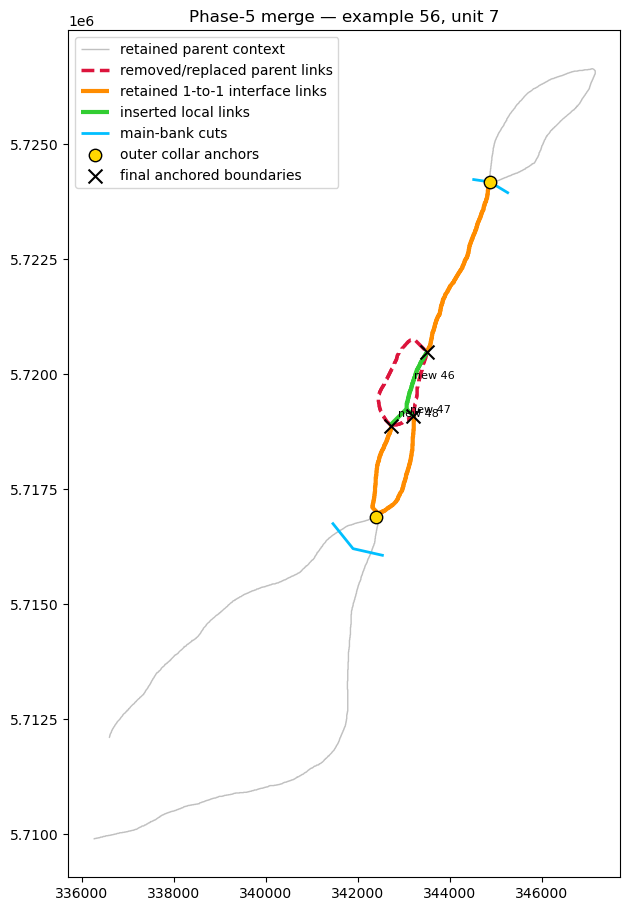

In [16]:
# Visual acceptance map: parent replacement domain versus merged local topology.
selected_attempt = phase5_raster_result.selected_attempt
map_bounds = box(*selected_attempt.bounds)
parent_map = case['links'].to_crs(merged_links.crs)
parent_visible = parent_map.loc[parent_map.geometry.intersects(map_bounds)].copy()
replacement_ids = set(phase5_merge.summary['replacement_parent_link_ids'])
parent_replacement = parent_visible.loc[parent_visible['id_link'].astype(int).isin(replacement_ids)]
parent_unchanged = parent_visible.loc[~parent_visible['id_link'].astype(int).isin(replacement_ids)]
retained_interface = merged_links.loc[merged_links['id_link'].astype(int).isin(interface_ids)]
merged_inserted = merged_links.loc[merged_links['id_link'].astype(int).isin(inserted_ids)]
cuts = gpd.read_file(phase5_raster_result.output_paths['main_bank_cuts']).to_crs(merged_links.crs)
outer_anchors = merged_nodes.loc[merged_nodes['id_node'].astype(int).isin([
    contract.source_splice_anchor_node_id, contract.sink_splice_anchor_node_id,
])]
anchored_boundary_ids = set(contract.anchored_upstream_boundary_node_ids) | set(contract.anchored_downstream_boundary_node_ids)
inner_boundaries = merged_nodes.loc[merged_nodes['id_node'].astype(int).isin(anchored_boundary_ids)]

fig, ax = plt.subplots(figsize=(11, 11))
parent_unchanged.plot(ax=ax, color='0.65', linewidth=1.0, alpha=0.7, label='retained parent context')
parent_replacement.plot(ax=ax, color='crimson', linewidth=2.5, linestyle='--', label='removed/replaced parent links')
retained_interface.plot(ax=ax, color='darkorange', linewidth=3.0, label='retained 1-to-1 interface links')
merged_inserted.plot(ax=ax, color='limegreen', linewidth=3.0, label='inserted local links')
cuts.plot(ax=ax, color='deepskyblue', linewidth=2.0, label='main-bank cuts')
outer_anchors.plot(ax=ax, color='gold', edgecolor='black', markersize=80, label='outer collar anchors', zorder=6)
inner_boundaries.plot(ax=ax, color='black', marker='x', markersize=100, label='final anchored boundaries', zorder=7)
for row in merged_inserted.itertuples(index=False):
    point = row.geometry.interpolate(0.5, normalized=True)
    ax.annotate(f'new {int(row.id_link)}', (point.x, point.y), fontsize=8)
ax.set_title(f'Phase-5 merge — example {EXAMPLE_ID}, unit {UNIT_ID}')
ax.set_aspect('equal')
ax.legend(loc='best')
plt.show()

### What to decide from this test

Accept the Phase-5 merge logic only if all four mechanical checks pass and the green local topology is a plausible replacement for the dashed red parent core. In particular, inspect whether the green geometry joins the black inner boundary nodes while the parent collar links continue to the gold outer anchors. The blue cut can lie farther outward because it is only computational context.

This test deliberately does **not** claim that the inserted links already contain correct final widths, lengths, slopes, resistance, or hierarchy fields. Those are the subject of Phase 6. The Phase-5 question is narrower: did we reconnect the locally regenerated topology to the correct parent graph while leaving unaffected parent products untouched?

## 11. Phase 6A — width and length inheritance

This section constructs the complete width and length layer. Strict unchanged one-to-one links inherit their parent measurements, reviewed routing widths, and samples. Only locally changed links are converted to ordered pixels in the bounded collapsed raster and remeasured. Anchored segmented-stub correction and routing-width evaluation then use the same functions as the full-raster workflow.

In [17]:
from network_variants.local_patch_products import materialize_local_patch_width_length_products

parent_width_dir = case['base_root'] / 'variant/widths'
phase6_products = materialize_local_patch_width_length_products(
    merge_result=phase5_merge,
    variant_result=phase5_variant,
    parent_width_links_path=parent_width_dir / 'links_with_width_families.gpkg',
    parent_nodes_path=case['nodes_path'],
    parent_width_samples_path=parent_width_dir / 'link_width_samples.csv',
    output_dir=phase5_root / 'products',
    example_id=EXAMPLE_ID,
    variant_id=f'local_unit_{UNIT_ID}',
    collapse_corridor_mode=CORRIDOR_MODE,
)
phase6_links = gpd.read_file(phase6_products.output_paths['links_with_width_families'])
phase6_samples = pd.read_csv(phase6_products.output_paths['link_width_samples'])
phase6_lineage = pd.read_csv(phase6_products.output_paths['product_lineage'])
display(pd.Series({
    'status': phase6_products.status,
    'complete link count': phase6_products.summary['link_count'],
    'inherited links': phase6_products.summary['inherited_link_count'],
    'locally recalculated links': phase6_products.summary['recalculated_link_count'],
    'locally recalculated link IDs': phase6_products.summary['recalculated_link_ids'],
    'segmented-stub corrections': phase6_products.summary['segmented_stub_width_inheritance']['applied_link_ids'],
}, name='value').to_frame())


/opt/anaconda3/envs/river-hierarchy-rivgraph/lib/python3.12/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/river-hierarchy-rivgraph/lib/python3.12/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/river-hierarchy-rivgraph/lib/python3.12/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is

,value
status,complete_width_length_products
complete link count,46
inherited links,43
locally recalculated links,3
locally recalculated link IDs,"[46, 47, 48]"
segmented-stub corrections,[48]


In [18]:
# Mechanical Phase-6 checks: unchanged values must be byte-for-value inherited,
# while measured samples may belong only to the explicitly changed set.
parent_width_links = gpd.read_file(parent_width_dir / 'links_with_width_families.gpkg').to_crs(phase6_links.crs)
parent_by_id = parent_width_links.set_index(parent_width_links['id_link'].astype(int), drop=False)
phase6_by_id = phase6_links.set_index(phase6_links['id_link'].astype(int), drop=False)
changed_phase6_ids = set(phase6_products.summary['recalculated_link_ids'])
inherited_phase6_ids = set(phase6_by_id.index) - changed_phase6_ids
audit_fields = [field for field in ['wid_adj_wet', 'wid_adj_total', 'wid_adj_routing', 'len', 'len_adj'] if field in parent_by_id.columns and field in phase6_by_id.columns]
inheritance_checks = []
for link_id in sorted(inherited_phase6_ids):
    for field in audit_fields:
        left = parent_by_id.loc[link_id, field]
        right = phase6_by_id.loc[link_id, field]
        equal = (pd.isna(left) and pd.isna(right)) or (np.isfinite(left) and np.isfinite(right) and np.isclose(left, right, rtol=0, atol=1e-9))
        inheritance_checks.append({'id_link': link_id, 'field': field, 'parent': left, 'local': right, 'exact_or_numeric_equal': bool(equal)})
inheritance_checks = pd.DataFrame(inheritance_checks)
phase6_test_summary = pd.Series({
    'output link count equals merged topology': len(phase6_links) == len(merged_links),
    'recalculated IDs equal Phase-5 inserted IDs': changed_phase6_ids == set(inserted_ids),
    'all inherited audit fields equal parent': bool(inheritance_checks['exact_or_numeric_equal'].all()),
    'all recalculated links have samples': changed_phase6_ids.issubset(set(phase6_samples['id_link'].astype(int))),
    'all routing widths positive': bool(pd.to_numeric(phase6_links['wid_adj_routing'], errors='coerce').gt(0).all()),
}, name='passed')
display(phase6_test_summary.to_frame())
if not phase6_test_summary.all():
    display(inheritance_checks.loc[~inheritance_checks['exact_or_numeric_equal']])
assert phase6_test_summary.all(), 'One or more Phase-6 inheritance checks failed.'


,passed
output link count equals merged topology,True
recalculated IDs equal Phase-5 inserted IDs,True
all inherited audit fields equal parent,True
all recalculated links have samples,True
all routing widths positive,True


### Compare locally recalculated links with the completed full-raster state

Changed link IDs are not expected to match between workflows. Each local link is therefore paired with the geometrically nearest full-raster link. Length should agree to numerical precision when topology agrees. Width differences around one raster pixel can occur because the local and full workflows independently reconstruct ordered centreline pixels; larger differences require inspection.

In [19]:
reference_states = sorted((case['base_root'].parents[1] / 'states').glob(f'*_unit_{UNIT_ID}'))
if not reference_states:
    print(f'No completed full-raster reference state found for unit {UNIT_ID}.')
    phase6_reference_comparison = pd.DataFrame()
else:
    reference_width_path = reference_states[0] / 'variant/widths/links_with_width_families.gpkg'
    reference_links = gpd.read_file(reference_width_path).to_crs(phase6_links.crs)
    comparison_rows = []
    for local_id in sorted(changed_phase6_ids):
        local_row = phase6_by_id.loc[local_id]
        distances = reference_links.geometry.hausdorff_distance(local_row.geometry)
        reference_row = reference_links.loc[distances.idxmin()]
        record = {
            'local_id_link': local_id,
            'reference_id_link': int(reference_row.id_link),
            'hausdorff_distance_m': float(distances.min()),
        }
        for field in ['len', 'len_adj', 'wid_adj_total', 'wid_adj_wet', 'wid_adj_routing']:
            if field not in phase6_by_id.columns or field not in reference_row.index:
                continue
            local_value = float(local_row[field])
            reference_value = float(reference_row[field])
            record[f'local_{field}'] = local_value
            record[f'reference_{field}'] = reference_value
            record[f'{field}_relative_difference'] = ((local_value - reference_value) / reference_value if reference_value else np.nan)
        comparison_rows.append(record)
    phase6_reference_comparison = pd.DataFrame(comparison_rows)
    display(phase6_reference_comparison)
    plot_rows = []
    for row in phase6_reference_comparison.to_dict('records'):
        for field in ['wid_adj_total', 'wid_adj_wet', 'wid_adj_routing']:
            if f'local_{field}' in row:
                plot_rows.extend([
                    {'local_id_link': row['local_id_link'], 'metric': field, 'workflow': 'local patch', 'value': row[f'local_{field}']},
                    {'local_id_link': row['local_id_link'], 'metric': field, 'workflow': 'full raster', 'value': row[f'reference_{field}']},
                ])
    px.bar(
        pd.DataFrame(plot_rows), x='local_id_link', y='value', color='workflow',
        facet_col='metric', barmode='group',
        title=f'Phase-6 local versus full-raster widths — example {EXAMPLE_ID}, unit {UNIT_ID}',
    ).show()


,local_id_link,reference_id_link,hausdorff_distance_m,local_len,reference_len,len_relative_difference,local_len_adj,reference_len_adj,len_adj_relative_difference,local_wid_adj_total,reference_wid_adj_total,wid_adj_total_relative_difference,local_wid_adj_wet,reference_wid_adj_wet,wid_adj_wet_relative_difference,local_wid_adj_routing,reference_wid_adj_routing,wid_adj_routing_relative_difference
0,46,18,9.313226e-10,1425.882871,1425.882871,-2.200571e-13,364.416224,407.067158,-1.047762e-01,1059.333197,1059.333197,-2.597126e-14,810.970663,819.421681,-0.010313,810.970663,819.421681,-0.010313
1,47,20,9.331398e-10,206.977036,206.977036,-1.988367e-13,206.977036,206.977036,-1.988367e-13,919.552916,919.552916,-8.347682e-13,912.259421,912.270335,-0.000012,527.498955,528.365547,-0.001640
2,48,19,4.656613e-10,502.287048,502.287048,3.757217e-14,502.287048,502.287048,3.757217e-14,344.639309,344.639309,0.000000e+00,337.407014,337.407014,0.000000,333.782355,334.307158,-0.001570


## 12. Phase 6B — hierarchy, slopes/heads, and equivalent resistance

This section runs the normal topology and hydraulic implementations on the complete Phase-6A network. The parent hydraulic table is supplied explicitly, so strict unchanged links inherit final slopes. Collapse components and the Phase-5 final node map are also supplied explicitly, so changed links enter the same collapsed-unit head solver as a conventional full-raster child. Equivalent-resistance solves reuse the experiment cache in production; this notebook uses a scratch cache.

In [20]:
from network_variants.hydraulic_context import SlopeConfig
from network_variants.local_patch_hydraulics import materialize_local_patch_hydraulic_products

experiment_dir = case['base_root'].parents[1]
sword_candidates = [
    Path('/Volumes/PhD/SWORD/v17c'),
    REPO_ROOT.parent / 'data/sword/v17c',
    REPO_ROOT / 'data/sword/v17c',
]
sword_node_source = next((path for path in sword_candidates if path.exists()), None)
if sword_node_source is None:
    raise FileNotFoundError('Set sword_node_source to the local SWORD v17c directory before Phase 6B.')

phase6b_result = materialize_local_patch_hydraulic_products(
    products_result=phase6_products,
    merge_result=phase5_merge,
    collapse_components_path=phase5_variant.output_paths['collapse_components'],
    experiment_dir=experiment_dir,
    parent_state_dir=case['base_root'],
    output_dir=phase5_root / 'phase6b',
    state_id=f'local_unit_{UNIT_ID}',
    slope_config=SlopeConfig(
        min_slope=1e-6, slope_profile_mode='reference_section',
        max_slope_for_k=0.009, section_slope_ratio_max=5.0,
    ),
    equivalent_solver_cache_dir=phase5_root / 'phase6b/equivalent_resistance/solve_cache',
    sword_node_source_path=sword_node_source,
)
display(pd.Series(phase6b_result.summary, name='value').to_frame())

,value
state_id,local_unit_7
parent_state_id,S000_base
generated_at,2026-08-14T08:54:52.002756+00:00
links_path,/private/tmp/river_hierarchy_local_patch_inves...
nodes_path,/private/tmp/river_hierarchy_local_patch_inves...
hydraulic_nodes_path,/private/tmp/river_hierarchy_local_patch_inves...
parent_link_hydraulic_context,/Volumes/PhD/river_hierarchy/network_variants/...
parent_node_hydraulic_context,/Volumes/PhD/river_hierarchy/network_variants/...
collapse_components_path,/private/tmp/river_hierarchy_local_patch_inves...
node_match_path,/private/tmp/river_hierarchy_local_patch_inves...


In [21]:
# Mechanical contract: exactly the changed links enter the local head solver;
# every other final routing slope is inherited exactly from the base state.
phase6b_hydraulic = pd.read_csv(phase6b_result.output_paths['link_hydraulic_context']).set_index('id_link')
parent_hydraulic = pd.read_csv(case['base_root'] / 'hydraulic_context/link_hydraulic_context.csv').set_index('id_link')
phase6b_manifest = json.loads(Path(phase6b_result.output_paths['hydraulic_context_manifest']).read_text())
solver_summary = phase6b_manifest['collapsed_unit_head_solver']
changed_ids = set(int(value) for value in phase6_products.summary['recalculated_link_ids'])
inherited_ids = sorted(set(phase6b_hydraulic.index.astype(int)) - changed_ids)
assert set(solver_summary['candidate_link_ids']) == changed_ids
assert set(solver_summary['applied_link_ids']) == changed_ids
assert np.array_equal(
    phase6b_hydraulic.loc[inherited_ids, 'slope_used'].to_numpy(),
    parent_hydraulic.loc[inherited_ids, 'slope_used'].to_numpy(),
    equal_nan=True,
)
display(pd.Series({
    'changed links expected': sorted(changed_ids),
    'head-solver candidates': solver_summary['candidate_link_ids'],
    'head-solver links changed': solver_summary['applied_link_ids'],
    'unchanged slopes inherited exactly': len(inherited_ids),
    'solved components': solver_summary['solved_component_ids'],
}, name='Phase-6B mechanical check').to_frame())

,Phase-6B mechanical check
changed links expected,"[46, 47, 48]"
head-solver candidates,"[46, 47, 48]"
head-solver links changed,"[46, 47, 48]"
unchanged slopes inherited exactly,43
solved components,[C1]


In [22]:
# Scientific comparison against the completed conventional child. Changed
# IDs are paired through the geometry matches established in Phase 6A.
if phase6_reference_comparison.empty or not reference_states:
    print('No completed full-raster child is available for a Phase-6B comparison.')
else:
    reference_state = reference_states[0]
    reference_hydraulic = pd.read_csv(reference_state / 'hydraulic_context/link_hydraulic_context.csv').set_index('id_link')
    slope_rows = []
    for match in phase6_reference_comparison.itertuples(index=False):
        local_id = int(match.local_id_link)
        reference_id = int(match.reference_id_link)
        local_slope = float(phase6b_hydraulic.at[local_id, 'slope_used'])
        reference_slope = float(reference_hydraulic.at[reference_id, 'slope_used'])
        slope_rows.append({
            'local_id_link': local_id, 'reference_id_link': reference_id,
            'local_slope': local_slope, 'reference_slope': reference_slope,
            'relative_difference': abs(local_slope - reference_slope) / abs(reference_slope),
            'local_method': phase6b_hydraulic.at[local_id, 'slope_source_method'],
            'reference_method': reference_hydraulic.at[reference_id, 'slope_source_method'],
        })
    phase6b_slope_comparison = pd.DataFrame(slope_rows)
    assert phase6b_slope_comparison['relative_difference'].max() < 1e-5
    display(phase6b_slope_comparison)

    hierarchy_files = ['unit_summary.csv', 'unit_metrics.csv', 'path_metrics.csv', 'bubble_summary.csv', 'bubble_equivalent_metrics.csv', 'bubble_edge_resistance.csv', 'bubble_node_heads.csv']
    hierarchy_counts = []
    for filename in hierarchy_files:
        local_table = pd.read_csv(Path(phase6b_result.output_paths['hierarchy']) / filename)
        reference_table = pd.read_csv(reference_state / 'hierarchy' / filename)
        hierarchy_counts.append({'file': filename, 'local_rows': len(local_table), 'reference_rows': len(reference_table), 'same': len(local_table) == len(reference_table)})
    hierarchy_count_comparison = pd.DataFrame(hierarchy_counts)
    assert hierarchy_count_comparison['same'].all()
    display(hierarchy_count_comparison)

    local_eq = pd.read_csv(Path(phase6b_result.output_paths['hierarchy']) / 'bubble_equivalent_metrics.csv')
    reference_eq = pd.read_csv(reference_state / 'hierarchy/bubble_equivalent_metrics.csv')
    eq_comparison = local_eq.merge(reference_eq, on=['compound_bubble_id', 'bubble_root_unit_id'], suffixes=('_local', '_reference'))
    for metric in ['K_eq', 'G_eq']:
        eq_comparison[f'{metric}_relative_difference'] = (eq_comparison[f'{metric}_local'] - eq_comparison[f'{metric}_reference']).abs() / eq_comparison[f'{metric}_reference'].abs().replace(0, np.nan)
    assert eq_comparison['K_eq_relative_difference'].max() < 0.002
    display(eq_comparison[['compound_bubble_id', 'bubble_root_unit_id', 'K_eq_local', 'K_eq_reference', 'K_eq_relative_difference', 'G_eq_relative_difference']])

,local_id_link,reference_id_link,local_slope,reference_slope,relative_difference,local_method,reference_method
0,46,18,0.000333,0.000333,1.737368e-08,collapsed_unit_path_relative_solver,collapsed_unit_path_relative_solver
1,47,20,0.000185,0.000185,2.153824e-07,collapsed_unit_path_relative_solver,collapsed_unit_path_relative_solver
2,48,19,0.000631,0.000631,2.600654e-08,collapsed_unit_path_relative_solver,collapsed_unit_path_relative_solver


,file,local_rows,reference_rows,same
0,unit_summary.csv,14,14,True
1,unit_metrics.csv,14,14,True
2,path_metrics.csv,31,31,True
3,bubble_summary.csv,9,9,True
4,bubble_equivalent_metrics.csv,9,9,True
5,bubble_edge_resistance.csv,35,35,True
6,bubble_node_heads.csv,30,30,True


,compound_bubble_id,bubble_root_unit_id,K_eq_local,K_eq_reference,K_eq_relative_difference,G_eq_relative_difference
0,1,14,1.759362e-07,1.759362e-07,0.000000e+00,0.000000e+00
1,2,13,5.082034e-08,5.082034e-08,0.000000e+00,0.000000e+00
2,3,12,4.543482e-08,4.543482e-08,0.000000e+00,0.000000e+00
3,4,11,1.971887e-07,1.971879e-07,3.896760e-06,3.896745e-06
4,5,9,2.962046e-07,2.962046e-07,0.000000e+00,0.000000e+00
5,6,7,2.546741e-07,2.544625e-07,8.315101e-04,8.308193e-04
6,7,6,3.339217e-07,3.339217e-07,0.000000e+00,0.000000e+00
7,8,5,9.455115e-07,9.455115e-07,4.479231e-16,4.402881e-16
8,9,2,2.769082e-06,2.769082e-06,0.000000e+00,0.000000e+00


## 13. Phase 7 — multi-unit reference validation

This is the reproducible acceptance test for example 56 units 6, 10, and 14. It runs Phases 2–6B independently for every unit, compares each result with its completed conventional full-raster state, and retains all scratch artifacts for inspection. The batch includes RivGraph calls, so `RUN_PHASE7_BATCH` is `False` by default to prevent an accidental rerun when using **Run All**. Set it to `True` deliberately.

The thresholds below are explicit research decisions, not hidden implementation constants. Exact inheritance and table-count checks allow no failures. Independently skeletonized changed geometry may differ by at most one raster pixel. Changed slopes may differ by at most 0.1%, and equivalent resistance by at most 0.5%, to accommodate the resulting sub-pixel centreline and width sampling differences without accepting a topology change.

In [23]:
# Reload during method development so this cell picks up local-patch fixes
# without requiring the earlier, expensive exploratory cells to be rerun.
import importlib
import network_variants.local_patch_products as local_patch_products_module
local_patch_products_module = importlib.reload(local_patch_products_module)
materialize_local_patch_width_length_products = local_patch_products_module.materialize_local_patch_width_length_products

PHASE7_CASES = [('56', 1, 'WN'), ('56', 15, 'WN')]
RUN_PHASE7_BATCH = True  # Change deliberately: this runs RivGraph three times.
PHASE7_LIMITS = {
    'changed_geometry_hausdorff_pixels': 1.01,
    'changed_width_relative_difference': 0.05,
    'changed_slope_relative_difference': 0.001,
    'equivalent_resistance_relative_difference': 0.005,
}

def _relative_difference(left, right):
    left, right = float(left), float(right)
    return abs(left - right) / abs(right) if np.isfinite(right) and right != 0 else np.nan

def run_phase7_validation_case(example_id, unit_id, exit_sides):
    case_i = load_case(str(example_id))
    planning_i = plan_local_patch(
        example_id=str(example_id), full_links=case_i['links'],
        unit_summary=case_i['unit_summary'], unit_link_membership=case_i['membership'],
        bubble_edge_resistance=case_i['bubble_edges'], selected_unit_ids=[int(unit_id)],
    )
    if not planning_i.is_safe:
        raise RuntimeError(f'{example_id} unit {unit_id}: topology plan failed: {planning_i.fallback_reason}')
    contract_i = planning_i.contract
    run_id = pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%SZ')
    root_i = SCRATCH_ROOT / f'phase7_{example_id}_unit_{unit_id}_{run_id}'
    raster_i = build_local_patch_base_raster(
        contract=contract_i, full_links=case_i['links'], full_nodes=case_i['nodes'],
        cleaned_mask_path=case_i['mask_path'], boundary_component_labels_path=case_i['labels_path'],
        reference_centerline_path=case_i['centerline_path'], output_dir=root_i / 'base_crop',
    )
    if not raster_i.is_safe:
        raise RuntimeError(f'{example_id} unit {unit_id}: no safe crop: {raster_i.fallback_reason}')
    variant_i = materialize_local_patch_variant(
        contract=contract_i, raster_result=raster_i, reviewed_links_path=case_i['links_path'],
        reviewed_nodes_path=case_i['nodes_path'], exit_sides=exit_sides,
        output_dir=root_i / 'local_variant',
    )
    merge_i = merge_local_patch_variant(
        contract=contract_i, raster_result=raster_i, variant_result=variant_i,
        parent_links_path=case_i['links_path'], parent_nodes_path=case_i['nodes_path'],
        output_dir=root_i / 'merge',
    )
    parent_width_dir_i = case_i['base_root'] / 'variant/widths'
    products_i = materialize_local_patch_width_length_products(
        merge_result=merge_i, variant_result=variant_i,
        parent_width_links_path=parent_width_dir_i / 'links_with_width_families.gpkg',
        parent_nodes_path=case_i['nodes_path'],
        parent_width_samples_path=parent_width_dir_i / 'link_width_samples.csv',
        output_dir=root_i / 'products', example_id=str(example_id),
        variant_id=f'local_unit_{unit_id}', collapse_corridor_mode=CORRIDOR_MODE,
    )
    hydraulics_i = materialize_local_patch_hydraulic_products(
        products_result=products_i, merge_result=merge_i,
        collapse_components_path=variant_i.output_paths['collapse_components'],
        experiment_dir=case_i['base_root'].parents[1], parent_state_dir=case_i['base_root'],
        output_dir=root_i / 'phase6b', state_id=f'local_unit_{unit_id}',
        slope_config=SlopeConfig(min_slope=1e-6, slope_profile_mode='reference_section', max_slope_for_k=0.009, section_slope_ratio_max=5.0),
        equivalent_solver_cache_dir=root_i / 'phase6b/equivalent_resistance/solve_cache',
        sword_node_source_path=sword_node_source,
    )

    reference_candidates = sorted((case_i['base_root'].parents[1] / 'states').glob(f'S*_unit_{unit_id}'))
    if not reference_candidates:
        raise FileNotFoundError(f'{example_id} unit {unit_id}: completed full-raster reference state not found.')
    reference_state = reference_candidates[0]
    local_links = gpd.read_file(products_i.output_paths['links_with_width_families'])
    reference_links = gpd.read_file(reference_state / 'variant/widths/links_with_width_families.gpkg').to_crs(local_links.crs)
    parent_links = gpd.read_file(parent_width_dir_i / 'links_with_width_families.gpkg').to_crs(local_links.crs)
    local_by_id = local_links.set_index(local_links['id_link'].astype(int), drop=False)
    parent_by_id_i = parent_links.set_index(parent_links['id_link'].astype(int), drop=False)
    changed = set(int(value) for value in products_i.summary['recalculated_link_ids'])
    inherited = sorted(set(local_by_id.index) - changed)

    inherited_width_failures = 0
    inherited_fields = [field for field in ['wid_adj_wet', 'wid_adj_total', 'wid_adj_routing', 'len', 'len_adj'] if field in local_by_id and field in parent_by_id_i]
    for link_id in inherited:
        for field in inherited_fields:
            left, right = local_by_id.at[link_id, field], parent_by_id_i.at[link_id, field]
            equal = (pd.isna(left) and pd.isna(right)) or np.isclose(float(left), float(right), rtol=0, atol=1e-9)
            inherited_width_failures += int(not equal)

    match_rows = []
    for local_id in sorted(changed):
        distances = reference_links.geometry.hausdorff_distance(local_by_id.loc[local_id].geometry)
        reference_row = reference_links.loc[distances.idxmin()]
        row = {'local_id_link': local_id, 'reference_id_link': int(reference_row.id_link), 'hausdorff_distance_m': float(distances.min())}
        for field in ['wid_adj_total', 'wid_adj_wet', 'wid_adj_routing']:
            if field in local_by_id and field in reference_row.index:
                row[f'{field}_relative_difference'] = _relative_difference(local_by_id.at[local_id, field], reference_row[field])
        match_rows.append(row)
    link_matches = pd.DataFrame(match_rows)

    local_hydraulic = pd.read_csv(hydraulics_i.output_paths['link_hydraulic_context']).set_index('id_link')
    parent_hydraulic_i = pd.read_csv(case_i['base_root'] / 'hydraulic_context/link_hydraulic_context.csv').set_index('id_link')
    reference_hydraulic = pd.read_csv(reference_state / 'hydraulic_context/link_hydraulic_context.csv').set_index('id_link')
    unchanged_slope_failures = int(~np.isclose(local_hydraulic.loc[inherited, 'slope_used'], parent_hydraulic_i.loc[inherited, 'slope_used'], rtol=0, atol=0, equal_nan=True).all())
    slope_differences = []
    for match in link_matches.itertuples(index=False):
        slope_differences.append(_relative_difference(local_hydraulic.at[int(match.local_id_link), 'slope_used'], reference_hydraulic.at[int(match.reference_id_link), 'slope_used']))
    link_matches['slope_relative_difference'] = slope_differences
    hydraulic_manifest = json.loads(Path(hydraulics_i.output_paths['hydraulic_context_manifest']).read_text())
    solver = hydraulic_manifest['collapsed_unit_head_solver']
    solver_scope_failures = len(changed.symmetric_difference(set(solver['candidate_link_ids']))) + len(changed.difference(set(solver['applied_link_ids'])))

    hierarchy_files = ['unit_summary.csv', 'unit_metrics.csv', 'path_metrics.csv', 'bubble_summary.csv', 'bubble_equivalent_metrics.csv', 'bubble_edge_resistance.csv', 'bubble_node_heads.csv']
    hierarchy_count_failures = sum(
        len(pd.read_csv(Path(hydraulics_i.output_paths['hierarchy']) / filename)) != len(pd.read_csv(reference_state / 'hierarchy' / filename))
        for filename in hierarchy_files
    )
    local_eq = pd.read_csv(Path(hydraulics_i.output_paths['hierarchy']) / 'bubble_equivalent_metrics.csv')
    reference_eq = pd.read_csv(reference_state / 'hierarchy/bubble_equivalent_metrics.csv')
    eq = local_eq.merge(reference_eq, on=['compound_bubble_id', 'bubble_root_unit_id'], suffixes=('_local', '_reference'))
    eq['K_eq_relative_difference'] = (eq['K_eq_local'] - eq['K_eq_reference']).abs() / eq['K_eq_reference'].abs().replace(0, np.nan)

    width_columns = [column for column in link_matches if column.endswith('_relative_difference') and not column.startswith('slope_')]
    max_width_difference = float(link_matches[width_columns].abs().max().max()) if width_columns else 0.0
    with rasterio.open(variant_i.output_paths['local_collapsed_mask']) as local_mask_source:
        local_pixel_size_m = float(max(abs(local_mask_source.transform.a), abs(local_mask_source.transform.e)))
    max_geometry_hausdorff_m = float(link_matches['hausdorff_distance_m'].max())
    metrics = {
        'crop_or_merge_failures': int(not raster_i.is_safe) + int(not merge_i.summary['validation_report']['is_valid']),
        'inherited_width_failures': inherited_width_failures,
        'nonunique_changed_geometry_matches': len(link_matches) - link_matches['reference_id_link'].nunique(),
        'local_pixel_size_m': local_pixel_size_m,
        'max_changed_geometry_hausdorff_m': max_geometry_hausdorff_m,
        'max_changed_geometry_hausdorff_pixels': max_geometry_hausdorff_m / local_pixel_size_m,
        'max_changed_width_relative_difference': max_width_difference,
        'head_solver_scope_failures': solver_scope_failures,
        'unchanged_slope_failures': unchanged_slope_failures,
        'max_changed_slope_relative_difference': float(link_matches['slope_relative_difference'].max()),
        'hierarchy_count_failures': int(hierarchy_count_failures),
        'max_equivalent_resistance_relative_difference': float(eq['K_eq_relative_difference'].max()) if not eq.empty else 0.0,
    }
    checks = {
        'crop and merged topology valid': metrics['crop_or_merge_failures'] == 0,
        'unchanged width/length fields inherited': metrics['inherited_width_failures'] == 0,
        'changed geometry matched one-to-one': metrics['nonunique_changed_geometry_matches'] == 0 and metrics['max_changed_geometry_hausdorff_pixels'] <= PHASE7_LIMITS['changed_geometry_hausdorff_pixels'],
        'changed widths within tolerance': metrics['max_changed_width_relative_difference'] <= PHASE7_LIMITS['changed_width_relative_difference'],
        'head solver covers changed links': metrics['head_solver_scope_failures'] == 0,
        'unchanged slopes inherited exactly': metrics['unchanged_slope_failures'] == 0,
        'changed slopes reproduce full raster': metrics['max_changed_slope_relative_difference'] <= PHASE7_LIMITS['changed_slope_relative_difference'],
        'hierarchy table counts reproduce full raster': metrics['hierarchy_count_failures'] == 0,
        'equivalent resistance within tolerance': metrics['max_equivalent_resistance_relative_difference'] <= PHASE7_LIMITS['equivalent_resistance_relative_difference'],
    }
    return {
        'example_id': str(example_id), 'unit_id': int(unit_id), 'root': root_i, 'case': case_i,
        'contract': contract_i, 'raster': raster_i, 'variant': variant_i, 'merge': merge_i,
        'products': products_i, 'hydraulics': hydraulics_i, 'reference_state': reference_state,
        'local_links': local_links, 'reference_links': reference_links, 'link_matches': link_matches,
        'equivalent_comparison': eq, 'metrics': metrics, 'checks': checks,
    }

In [24]:
# Preserve completed cases when a later case fails and this cell is rerun.
phase7_results = globals().get('phase7_results', {})
if not RUN_PHASE7_BATCH:
    print('Phase-7 batch not run. Set RUN_PHASE7_BATCH = True in the previous cell, then rerun this cell.')
else:
    for example_id, unit_id, exit_sides in PHASE7_CASES:
        if (example_id, unit_id) in phase7_results:
            print(f'Reusing completed Phase-7 result: example {example_id}, unit {unit_id}.')
            continue
        print(f'Running Phase 7: example {example_id}, unit {unit_id} ...')
        phase7_results[(example_id, unit_id)] = run_phase7_validation_case(example_id, unit_id, exit_sides)

    # Refresh acceptance decisions for cached results after a threshold or
    # diagnostic definition changes; no RivGraph work is repeated.
    for result_i in phase7_results.values():
        metrics_i = result_i['metrics']
        if 'max_changed_geometry_hausdorff_pixels' not in metrics_i:
            with rasterio.open(result_i['variant'].output_paths['local_collapsed_mask']) as source:
                pixel_size_i = float(max(abs(source.transform.a), abs(source.transform.e)))
            metrics_i['local_pixel_size_m'] = pixel_size_i
            metrics_i['max_changed_geometry_hausdorff_pixels'] = metrics_i['max_changed_geometry_hausdorff_m'] / pixel_size_i
        result_i['checks']['changed geometry matched one-to-one'] = (
            metrics_i['nonunique_changed_geometry_matches'] == 0
            and metrics_i['max_changed_geometry_hausdorff_pixels'] <= PHASE7_LIMITS['changed_geometry_hausdorff_pixels']
        )
        result_i['checks']['changed slopes reproduce full raster'] = (
            metrics_i['max_changed_slope_relative_difference'] <= PHASE7_LIMITS['changed_slope_relative_difference']
        )

    check_rows = []
    metric_rows = []
    for (example_id, unit_id), result_i in phase7_results.items():
        for check, passed in result_i['checks'].items():
            check_rows.append({'example_id': example_id, 'unit_id': unit_id, 'check': check, 'passed': bool(passed)})
        metric_rows.append({'example_id': example_id, 'unit_id': unit_id, **result_i['metrics'], 'scratch_output': str(result_i['root'])})
    phase7_checks = pd.DataFrame(check_rows)
    phase7_metrics = pd.DataFrame(metric_rows)
    display(phase7_metrics)
    display(phase7_checks.pivot(index='check', columns='unit_id', values='passed'))
    phase7_all_checks_passed = bool(phase7_checks['passed'].all())
    if phase7_all_checks_passed:
        print('All Phase-7 acceptance checks passed.')
    else:
        print('One or more Phase-7 checks need review; continue to the maps below.')
        display(phase7_checks.loc[~phase7_checks['passed']])

Running Phase 7: example 56, unit 1 ...


/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude e

Running Phase 7: example 56, unit 15 ...


/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/opt/anaconda3/envs/river-hierarchy-rivgraph/lib/python3.12/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

,example_id,unit_id,crop_or_merge_failures,inherited_width_failures,nonunique_changed_geometry_matches,local_pixel_size_m,max_changed_geometry_hausdorff_m,max_changed_geometry_hausdorff_pixels,max_changed_width_relative_difference,head_solver_scope_failures,unchanged_slope_failures,max_changed_slope_relative_difference,hierarchy_count_failures,max_equivalent_resistance_relative_difference,scratch_output
0,56,1,0,0,0,7.317743,5.174426,0.707107,0.050242,0,0,0.001049,0,0.001457,/tmp/river_hierarchy_local_patch_investigation...
1,56,15,0,0,0,7.317743,5.174426,0.707107,0.001118,0,0,0.000921,0,0.000004,/tmp/river_hierarchy_local_patch_investigation...


unit_id,1,15
check,,
changed geometry matched one-to-one,True,True
changed slopes reproduce full raster,False,True
changed widths within tolerance,False,True
crop and merged topology valid,True,True
equivalent resistance within tolerance,True,True
head solver covers changed links,True,True
hierarchy table counts reproduce full raster,True,True
unchanged slopes inherited exactly,True,True
unchanged width/length fields inherited,True,True


One or more Phase-7 checks need review; continue to the maps below.


,example_id,unit_id,check,passed
3,56,1,changed widths within tolerance,False
6,56,1,changed slopes reproduce full raster,False


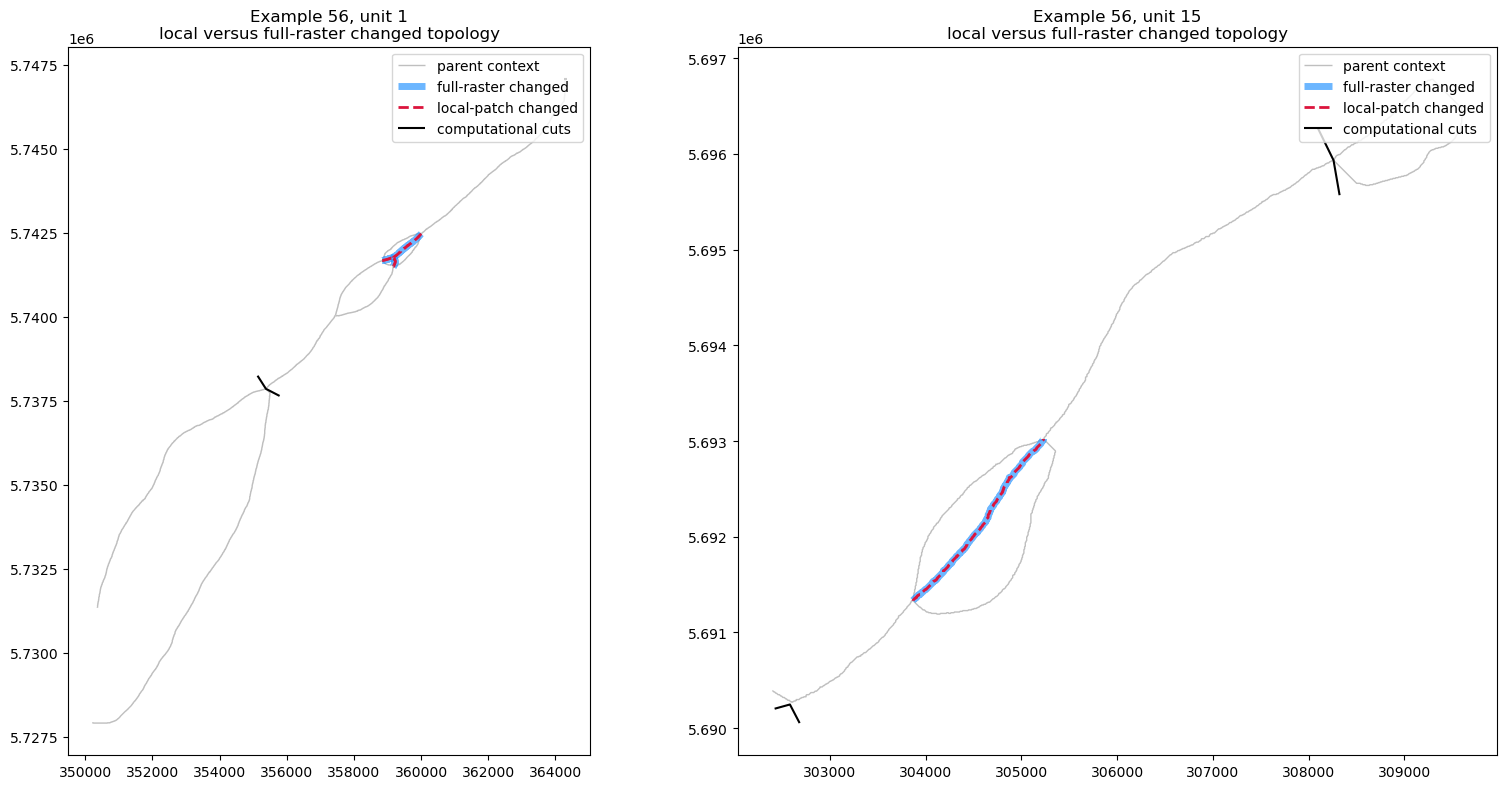

In [25]:
# Visual verification remains important even when all numerical checks pass.
if phase7_results:
    fig, axes = plt.subplots(1, len(phase7_results), figsize=(8 * len(phase7_results), 8), squeeze=False)
    for ax, ((example_id, unit_id), result_i) in zip(axes[0], phase7_results.items()):
        local_links = result_i['local_links']
        changed_ids = set(result_i['products'].summary['recalculated_link_ids'])
        local_changed = local_links.loc[local_links['id_link'].astype(int).isin(changed_ids)]
        reference_ids = set(result_i['link_matches']['reference_id_link'].astype(int))
        reference_changed = result_i['reference_links'].loc[result_i['reference_links']['id_link'].astype(int).isin(reference_ids)]
        bounds = box(*result_i['raster'].selected_attempt.bounds)
        parent_visible = result_i['case']['links'].to_crs(local_links.crs)
        parent_visible = parent_visible.loc[parent_visible.geometry.intersects(bounds)]
        parent_visible.plot(ax=ax, color='0.75', linewidth=1.0, label='parent context')
        reference_changed.plot(ax=ax, color='dodgerblue', linewidth=5, alpha=0.65, label='full-raster changed')
        local_changed.plot(ax=ax, color='crimson', linewidth=2, linestyle='--', label='local-patch changed')
        gpd.read_file(result_i['raster'].output_paths['main_bank_cuts']).to_crs(local_links.crs).plot(ax=ax, color='black', linewidth=1.5, label='computational cuts')
        ax.set_title(f'Example {example_id}, unit {unit_id}\nlocal versus full-raster changed topology')
        ax.set_aspect('equal')
        ax.legend(loc='best')
    plt.tight_layout()
    plt.show()

In [30]:
phase7_example15_unit131 = run_phase7_validation_case('56', 1, 'WN')
display(pd.Series(phase7_example15_unit131['metrics'], name='value').to_frame())
display(pd.Series(phase7_example15_unit131['checks'], name='passed').to_frame())

/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(
/Users/6256481/Code/river-hierarchy/network_variants/local_patch_merge.py:265: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude e

,value
crop_or_merge_failures,0.000000
inherited_width_failures,0.000000
nonunique_changed_geometry_matches,0.000000
local_pixel_size_m,7.317743
max_changed_geometry_hausdorff_m,5.174426
max_changed_geometry_hausdorff_pixels,0.707107
max_changed_width_relative_difference,0.050242
head_solver_scope_failures,0.000000
unchanged_slope_failures,0.000000
max_changed_slope_relative_difference,0.001049


,passed
crop and merged topology valid,True
unchanged width/length fields inherited,True
changed geometry matched one-to-one,True
changed widths within tolerance,False
head solver covers changed links,True
unchanged slopes inherited exactly,True
changed slopes reproduce full raster,False
hierarchy table counts reproduce full raster,True
equivalent resistance within tolerance,True


### Follow-up complex case: example 15, unit 131

After all three example-56 cases pass, run the following in a new cell. This case is deliberately separate because it is a hydraulically open member of a large compound domain and its accepted crop is substantially larger.

```python
phase7_example15_unit131 = run_phase7_validation_case('15', 131, 'SN')
display(pd.Series(phase7_example15_unit131['metrics'], name='value').to_frame())
display(pd.Series(phase7_example15_unit131['checks'], name='passed').to_frame())
```

`SN` is the reviewed global exit-side setting recorded by the completed example-15 experiment. It is provenance only; the local RivGraph direction is derived independently from the source and sink cuts.

## 14. Unit 7 routing-width optimizer investigation

This section diagnoses the example-56 unit-7 routing-width disagreement found in the production local-patch test. The raster masks and changed geometries already match the conventional child, so this section isolates the adaptive two-ended routing solver. It checks whether the optimum lies on an adaptive scale boundary, reproduces the persisted L-BFGS result, compares the nearly identical local/full inputs, and evaluates deterministic secondary optimizers. No files are modified.

In [27]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from network_variants.adaptive_routing_solver import (
    AdaptiveSolverConfig, adaptive_evidence_parameters, solve_adaptive_two_ended,
)

_unit7_start = Path.cwd().resolve()
REPO_ROOT = next(path for path in (_unit7_start, *_unit7_start.parents) if (path / 'network_variants').is_dir())

UNIT7_LOCAL_STATE = REPO_ROOT / 'network_variants/output/56_local_patch_independent_test__anchored/states/S007_unit_7'
UNIT7_FULL_STATE = REPO_ROOT / 'network_variants/output/56_indep__anchored/states/S007_unit_7'
UNIT7_SOLVER_COLUMNS = [
    'id_link', 'id_us_node', 'id_ds_node', 'wid_adj_wet',
    'routing_context_width_us', 'routing_context_width_ds',
    'width_model_prediction', 'width_model_probability',
    'upstream_continuity_abs_deviation', 'opposition_cos_trimmed_mean',
]

def load_scoped_solver_input(state_dir):
    audit = pd.read_csv(state_dir / 'variant/widths/routing_width_application.csv')
    # Persisted fixed rows retain their parent model provenance. They were
    # not candidates in this child solve, so restore the actual scoped mask.
    audit['width_model_prediction_solver'] = np.where(
        audit['width_model_evaluation_scope'].fillna(False).astype(bool),
        pd.to_numeric(audit['width_model_prediction'], errors='coerce').fillna(0), 0,
    ).astype(int)
    solver_input = audit[UNIT7_SOLVER_COLUMNS].copy()
    solver_input['width_model_prediction'] = audit['width_model_prediction_solver']
    return audit, solver_input

unit7_local_audit, unit7_local_solver_input = load_scoped_solver_input(UNIT7_LOCAL_STATE)
unit7_full_audit, unit7_full_solver_input = load_scoped_solver_input(UNIT7_FULL_STATE)
unit7_reproduced, unit7_reproduced_diagnostics = solve_adaptive_two_ended(
    unit7_local_solver_input, config=AdaptiveSolverConfig(upstream_weight=2.0, downstream_weight=1.0),
)
display(pd.Series(unit7_reproduced_diagnostics, name='reproduced local solve').to_frame())

comparison_columns = [
    'id_link', 'wid_adj_wet', 'width_model_probability',
    'upstream_continuity_abs_deviation', 'opposition_cos_trimmed_mean',
    'adaptive_min_scale', 'adaptive_max_scale', 'comparison_scale_factor', 'comparison_status',
]
local_candidates = unit7_local_audit.loc[unit7_local_audit['width_model_evaluation_scope'].fillna(False) & unit7_local_audit['width_model_prediction'].eq(1), comparison_columns].copy()
full_candidates = unit7_full_audit.loc[unit7_full_audit['width_model_evaluation_scope'].fillna(False) & unit7_full_audit['width_model_prediction'].eq(1), comparison_columns].copy()
candidate_pairs = []
for local_row in local_candidates.itertuples(index=False):
    full_row = full_candidates.iloc[(full_candidates['wid_adj_wet'] - local_row.wid_adj_wet).abs().argmin()]
    candidate_pairs.append({
        'local_link': int(local_row.id_link), 'full_link': int(full_row.id_link),
        'local_wet_width': float(local_row.wid_adj_wet), 'full_wet_width': float(full_row.wid_adj_wet),
        'wet_width_relative_difference': abs(float(local_row.wid_adj_wet) - float(full_row.wid_adj_wet)) / float(full_row.wid_adj_wet),
        'lower_bound': float(local_row.adaptive_min_scale), 'upper_bound': float(local_row.adaptive_max_scale),
        'original_selected_scale': float(full_row.comparison_scale_factor),
        'distance_from_lower_bound': float(full_row.comparison_scale_factor - local_row.adaptive_min_scale),
        'distance_from_upper_bound': float(local_row.adaptive_max_scale - full_row.comparison_scale_factor),
    })
unit7_candidate_comparison = pd.DataFrame(candidate_pairs)
display(unit7_candidate_comparison)

,reproduced local solve
success,True
optimizer_success,False
acceptance_status,accepted_numerical_stagnation
message,ABNORMAL_TERMINATION_IN_LNSRCH
iterations,6
objective,0.023176
candidate_count,2
adaptive_flag_count,0
recognized_numerical_stagnation,True
finite_solution,True


,local_link,full_link,local_wet_width,full_wet_width,wet_width_relative_difference,lower_bound,upper_bound,original_selected_scale,distance_from_lower_bound,distance_from_upper_bound
0,47,20,912.259421,912.270335,0.000012,0.107797,5.746459,0.579177,0.471379,5.167283
1,48,19,337.407014,337.407014,0.000000,0.125865,5.375475,0.990813,0.864948,4.384662


In [28]:
def adaptive_objective_contract(frame, config=AdaptiveSolverConfig(upstream_weight=2.0, downstream_weight=1.0)):
    frame = frame.copy().reset_index(drop=True)
    candidate_mask = frame['width_model_prediction'].eq(1).fillna(False).to_numpy(bool)
    candidate_positions = np.flatnonzero(candidate_mask)
    candidates = frame.loc[candidate_mask].copy()
    evidence = adaptive_evidence_parameters(candidates, config=config)
    us_nodes = frame['id_us_node'].to_numpy(int); ds_nodes = frame['id_ds_node'].to_numpy(int)
    us_context = frame['routing_context_width_us'].to_numpy(float); ds_context = frame['routing_context_width_ds'].to_numpy(float)
    relevant_nodes = sorted(set(candidates['id_us_node'].astype(int)) | set(candidates['id_ds_node'].astype(int)))
    incoming = {node: np.flatnonzero(ds_nodes == node) for node in relevant_nodes}
    outgoing = {node: np.flatnonzero(us_nodes == node) for node in relevant_nodes}
    max_deviation = candidates.groupby('id_us_node')['upstream_continuity_abs_deviation'].max().to_dict()
    raw_weights = evidence['adaptive_raw_penalty_weight'].to_numpy(float)
    upstream_nodes = set(candidates['id_us_node'].astype(int)); downstream_nodes = set(candidates['id_ds_node'].astype(int))
    def objective(log_scales):
        scales = np.ones(len(frame), dtype=float); scales[candidate_positions] = np.exp(log_scales)
        loss = float(np.sum(raw_weights * np.square(log_scales)))
        for node in relevant_nodes:
            width_in = float(np.sum(ds_context[incoming[node]] * scales[incoming[node]]))
            width_out = float(np.sum(us_context[outgoing[node]] * scales[outgoing[node]]))
            if width_in <= 0 or width_out <= 0: loss += 1e6; continue
            log_ratio = float(np.log(width_out / width_in)); weight = 0.0
            if node in upstream_nodes:
                weight += config.upstream_weight * (1.0 + min(np.log1p(max(float(max_deviation.get(node, 0.0)), 0.0)), 2.0))
            if node in downstream_nodes: weight += config.downstream_weight
            absolute = abs(log_ratio); robust = 0.5 * log_ratio**2 if absolute <= 0.5 else 0.5 * (absolute - 0.25)
            loss += weight * robust
        return float(loss)
    lower = np.log(evidence['adaptive_min_scale'].to_numpy(float)); upper = np.log(evidence['adaptive_max_scale'].to_numpy(float))
    return objective, lower, upper, candidates, evidence

unit7_objective, unit7_lower, unit7_upper, unit7_candidates, unit7_evidence = adaptive_objective_contract(unit7_local_solver_input)
unit7_attempts = []
for method, options in [
    ('L-BFGS-B', {'maxiter': 500, 'ftol': 1e-12, 'gtol': 1e-8}),
    ('Powell', {'maxiter': 2000, 'ftol': 1e-12, 'xtol': 1e-10}),
    ('SLSQP', {'maxiter': 1000, 'ftol': 1e-12}),
]:
    result_i = minimize(unit7_objective, np.zeros(len(unit7_lower)), method=method, bounds=list(zip(unit7_lower, unit7_upper)), options=options)
    scales_i = np.exp(result_i.x)
    unit7_attempts.append({
        'method': method, 'success': bool(result_i.success), 'message': str(result_i.message),
        'iterations': int(getattr(result_i, 'nit', 0)), 'objective': float(result_i.fun),
        **{f'scale_link_{int(link_id)}': float(scale) for link_id, scale in zip(unit7_candidates['id_link'], scales_i)},
        'minimum_log_distance_to_bound': float(np.min(np.minimum(result_i.x - unit7_lower, unit7_upper - result_i.x))),
    })
unit7_optimizer_comparison = pd.DataFrame(unit7_attempts)
display(unit7_optimizer_comparison)
print('A positive minimum_log_distance_to_bound means the solution is inside every adaptive bound.')

successful_attempt = next(row for row in unit7_attempts if row['method'] == 'Powell' and row['success'])
scale_by_link = {int(row.id_link): 1.0 for row in unit7_local_solver_input.itertuples(index=False)}
for link_id in unit7_candidates['id_link'].astype(int):
    scale_by_link[link_id] = successful_attempt[f'scale_link_{link_id}']
junction_rows = []
candidate_nodes = sorted(set(unit7_candidates['id_us_node'].astype(int)) | set(unit7_candidates['id_ds_node'].astype(int)))
for node_id in candidate_nodes:
    incoming = unit7_local_solver_input.loc[unit7_local_solver_input['id_ds_node'].astype(int).eq(node_id)]
    outgoing = unit7_local_solver_input.loc[unit7_local_solver_input['id_us_node'].astype(int).eq(node_id)]
    width_in = sum(float(row.routing_context_width_ds) * scale_by_link[int(row.id_link)] for row in incoming.itertuples(index=False))
    width_out = sum(float(row.routing_context_width_us) * scale_by_link[int(row.id_link)] for row in outgoing.itertuples(index=False))
    log_ratio = float(np.log(width_out / width_in))
    junction_rows.append({'node_id': node_id, 'width_in': width_in, 'width_out': width_out, 'log_ratio': log_ratio, 'distance_to_huber_kink_abs_log_ratio_0_5': abs(abs(log_ratio) - 0.5)})
display(pd.DataFrame(junction_rows))

,method,success,message,iterations,objective,scale_link_47,scale_link_48,minimum_log_distance_to_bound
0,L-BFGS-B,False,ABNORMAL_TERMINATION_IN_LNSRCH,6,0.023176,0.579183,0.990813,1.681368
1,Powell,True,Optimization terminated successfully.,4,0.023176,0.579183,0.990813,1.681368
2,SLSQP,True,Optimization terminated successfully,6,0.023176,0.579183,0.990813,1.681368


A positive minimum_log_distance_to_bound means the solution is inside every adaptive bound.


,node_id,width_in,width_out,log_ratio,distance_to_huber_kink_abs_log_ratio_0_5
0,14,520.488576,528.365398,0.015020,0.484980
1,15,337.407014,334.307168,-0.009230,0.490770
2,32,862.672566,819.421681,-0.051436,0.448564


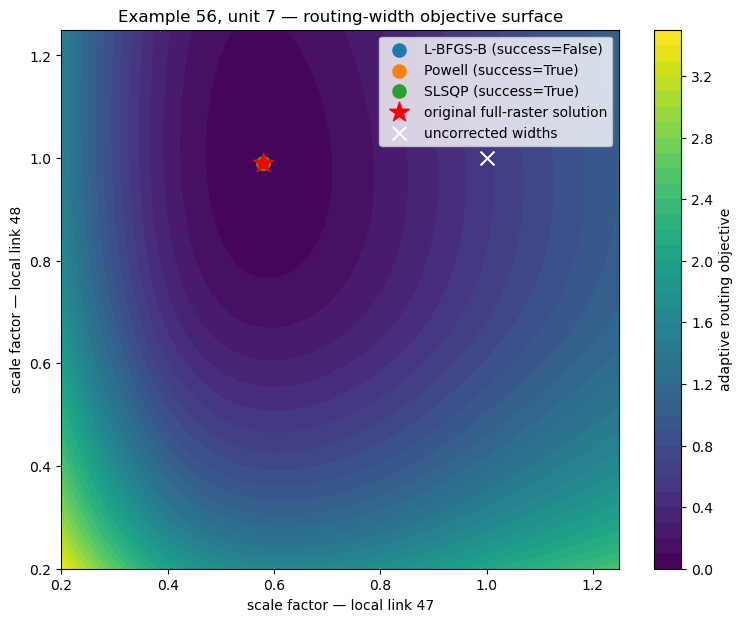

In [29]:
if len(unit7_candidates) != 2:
    print(f'Objective-surface plot requires exactly two candidates; found {len(unit7_candidates)}.')
else:
    scale_1 = np.linspace(max(np.exp(unit7_lower[0]), 0.2), min(np.exp(unit7_upper[0]), 1.25), 180)
    scale_2 = np.linspace(max(np.exp(unit7_lower[1]), 0.2), min(np.exp(unit7_upper[1]), 1.25), 180)
    xx, yy = np.meshgrid(scale_1, scale_2)
    zz = np.array([unit7_objective(np.log([x, y])) for x, y in zip(xx.ravel(), yy.ravel())]).reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(9, 7))
    contour = ax.contourf(xx, yy, zz, levels=35, cmap='viridis')
    fig.colorbar(contour, ax=ax, label='adaptive routing objective')
    for attempt in unit7_attempts:
        ax.scatter(attempt[f'scale_link_{int(unit7_candidates.iloc[0].id_link)}'], attempt[f'scale_link_{int(unit7_candidates.iloc[1].id_link)}'], s=90, label=f"{attempt['method']} (success={attempt['success']})")
    original_scales = unit7_candidate_comparison.set_index('local_link').loc[unit7_candidates['id_link'].astype(int), 'original_selected_scale'].to_numpy(float)
    ax.scatter(original_scales[0], original_scales[1], marker='*', s=220, color='red', label='original full-raster solution')
    ax.scatter(1.0, 1.0, marker='x', s=100, color='white', label='uncorrected widths')
    ax.set_xlabel(f"scale factor — local link {int(unit7_candidates.iloc[0].id_link)}")
    ax.set_ylabel(f"scale factor — local link {int(unit7_candidates.iloc[1].id_link)}")
    ax.set_title('Example 56, unit 7 — routing-width objective surface')
    ax.legend(loc='best')
    plt.show()

## 15. Saved fallback diagnostics — independently runnable

The sections below inspect artifacts already saved by completed local-patch attempts; they do **not** rerun a collapse or modify an experiment. Every code cell bootstraps the repository path and reloads `local_patch_fallback_diagnostics`, so any one section can be run immediately after opening or restarting this notebook. The representative cases cover all four top-level fallback groups and split the dominant cut-terminal group into its three distinct forms.

A crucial distinction for interpreting these maps is that the **computational cut** and the **final anchored interface** do not have to be the same location. The cut supplies enough upstream/downstream water context for a stable local RivGraph solve. The final anchored product should instead be trimmed at the selected unit boundary, retain the outside base link exactly one-to-one, and reuse the shared base boundary node. A computational terminal should therefore not be forced to inherit an outer anchor node ID merely because that node selected the collar direction. Dashed grey lines in the execution-stage maps are the unchanged base/reference network; solid green lines are raw local RivGraph output.


### 15.1 Small cut-terminal tolerance miss — example 3, unit 18

The correct outlet exists and has the correct RivGraph role, but it is about 90 m from the downstream cut while the fixed merge tolerance is about 75 m. Base collar link 55 (node 36 to node 37) is only about 155 m long, so the 1,000 m context rule places the computational cut about 794 m beyond node 37 along the reference centerline. Node 37 is therefore not expected at the computational cut. The failure is caused by conflating the extended computational terminal with base node 37; after the local solve, the result should be trimmed at base node 36 and link 55 plus node 37 should remain exact base-network objects.


,value
example_id,03
mode,indep
state_id,S004_unit_18
fallback_stage,execution
fallback_code,ValueError
fallback_reason,Downstream cut has 0 local terminal candidates...
planning_status,safe
local_artifacts_available,True


,child_id_node,is_inlet,is_outlet,x,y,distance_to_upstream_cut_m,distance_to_downstream_cut_m,fixed_merge_tolerance_m
0,0,True,False,246637.228574,7.599087e+06,23.626629,2470.568671,74.988
1,2,False,True,249139.945308,7.598778e+06,2537.628729,90.339051,74.988


(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Example 03 S004_unit_18 — cut/terminal audit'}>)

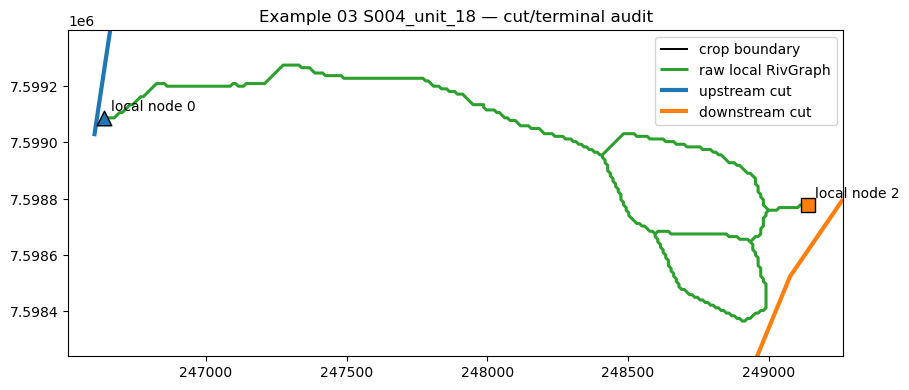

In [1]:
from pathlib import Path
import sys
import pandas as pd
from importlib import reload
REPO_ROOT = next(p for start in [Path.cwd().resolve()] for p in (start, *start.parents) if (p / 'network_variants').is_dir() and (p / 'RAPID').is_dir())
if str(REPO_ROOT) not in sys.path: sys.path.insert(0, str(REPO_ROOT))
from network_variants import local_patch_fallback_diagnostics as fallback_diag
fallback_diag = reload(fallback_diag)
small_terminal_case = fallback_diag.load_fallback_case('03', 'indep', 'S004_unit_18', repo_root=REPO_ROOT)
display(fallback_diag.fallback_summary(small_terminal_case).to_frame())
display(fallback_diag.terminal_audit(small_terminal_case))
fallback_diag.plot_terminal_case(small_terminal_case)


### 15.2 Long-collar interface mismatch — example 2, unit 5

This is the repeated example-2 failure. It affects every unit in compound bubble 5, not only unit 5: 13 units reach this same downstream failure and unit 13 fails earlier at an ambiguous planning continuation. Downstream computational collar link 5 is about 21.4 km long, the cut is placed at its distant outer node, and the local skeleton outlet terminates about 10.75 km before the cut. Because the final anchored result will retain the reference-network collar and trim back to the selected unit boundaries, the computational crop does not need to reproduce all 21.4 km of link 5. This case should drive a bounded context cut plus exact one-to-one retention of the outside base anchor; it must not be accepted by merely increasing a distance tolerance.


,value
example_id,02
mode,indep
state_id,S004_unit_5
fallback_stage,execution
fallback_code,ValueError
fallback_reason,Downstream cut has 0 local terminal candidates...
planning_status,safe
local_artifacts_available,True


,child_id_node,is_inlet,is_outlet,x,y,distance_to_upstream_cut_m,distance_to_downstream_cut_m,fixed_merge_tolerance_m
0,0,False,True,678537.781664,5.894790e+06,46412.778611,10753.278576,69.609
1,27,True,False,706868.512839,5.857271e+06,22.569211,55787.904592,69.609


{'base_downstream_node_id': 4,
 'base_link_id': 5,
 'base_upstream_node_id': 5,
 'change_policy': 'allow_retain_replace_split_or_merge',
 'domain_boundary_node_id': 5,
 'match_expectation': 'prefer_strict_unchanged_1to1',
 'outer_splice_anchor_node_id': 4,
 'role': 'downstream',
 'unit_membership_count': 0}

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Example 02 S004_unit_5 — cut/terminal audit'}>)

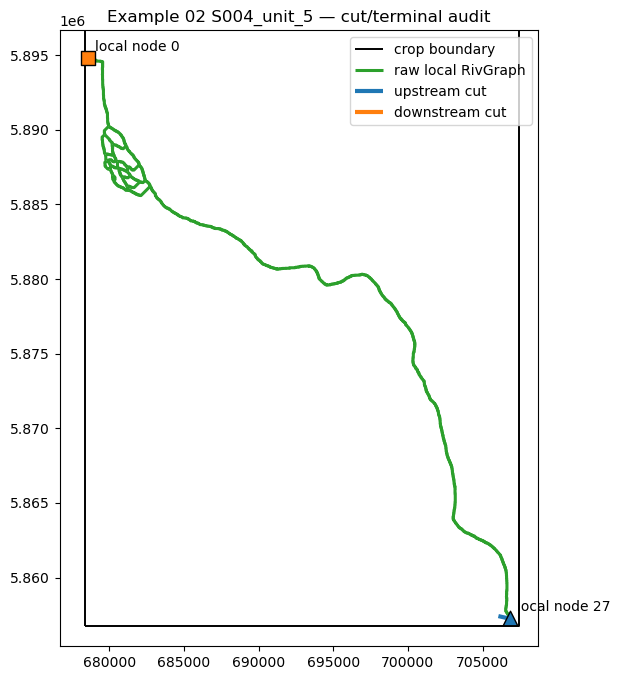

In [2]:
from pathlib import Path
import sys
from importlib import reload
REPO_ROOT = next(p for start in [Path.cwd().resolve()] for p in (start, *start.parents) if (p / 'network_variants').is_dir() and (p / 'RAPID').is_dir())
if str(REPO_ROOT) not in sys.path: sys.path.insert(0, str(REPO_ROOT))
from network_variants import local_patch_fallback_diagnostics as fallback_diag
fallback_diag = reload(fallback_diag)
long_collar_case = fallback_diag.load_fallback_case('02', 'indep', 'S004_unit_5', repo_root=REPO_ROOT)
display(fallback_diag.fallback_summary(long_collar_case).to_frame())
display(fallback_diag.terminal_audit(long_collar_case))
display(fallback_diag.planning_interface_audit(long_collar_case) if long_collar_case['planning'].get('contract') is None else long_collar_case['planning']['contract']['downstream_collar'])
fallback_diag.plot_terminal_case(long_collar_case)


### 15.3 Multiple compatible terminals at one cut — example 3, unit 3

Two raw outlets lie within the downstream tolerance. The map and table show whether this is a short skeleton spur that can be pruned deterministically or a genuine ambiguous topology that should continue to fall back.


In [ ]:
from pathlib import Path
import sys
from importlib import reload
REPO_ROOT = next(p for start in [Path.cwd().resolve()] for p in (start, *start.parents) if (p / 'network_variants').is_dir() and (p / 'RAPID').is_dir())
if str(REPO_ROOT) not in sys.path: sys.path.insert(0, str(REPO_ROOT))
from network_variants import local_patch_fallback_diagnostics as fallback_diag
fallback_diag = reload(fallback_diag)
multiple_terminal_case = fallback_diag.load_fallback_case('03', 'indep', 'S011_unit_3', repo_root=REPO_ROOT)
display(fallback_diag.fallback_summary(multiple_terminal_case).to_frame())
display(fallback_diag.terminal_audit(multiple_terminal_case).sort_values('distance_to_downstream_cut_m'))
fallback_diag.plot_terminal_case(multiple_terminal_case)


### 15.4 Multiple child nodes mapping to one parent — example 3, unit 5

This section isolates the parent node named in the fallback and displays every competing local assignment. Local node 2 is an exact spatial match to base node 8. A different inlet terminal, local node 1, is about 830 m away but is forcibly assigned to node 8 because the extended computational cut used node 8 as its logical outer anchor. This is direct evidence that computational cut terminals and final anchored node identities must be separated. The exact spatial match should define node 8; the remote cut terminal should be used only for local orientation/context and removed when the graph is trimmed back to the anchored boundary.


In [ ]:
from pathlib import Path
import sys
from importlib import reload
REPO_ROOT = next(p for start in [Path.cwd().resolve()] for p in (start, *start.parents) if (p / 'network_variants').is_dir() and (p / 'RAPID').is_dir())
if str(REPO_ROOT) not in sys.path: sys.path.insert(0, str(REPO_ROOT))
from network_variants import local_patch_fallback_diagnostics as fallback_diag
fallback_diag = reload(fallback_diag)
node_collision_case = fallback_diag.load_fallback_case('03', 'indep', 'S001_unit_5', repo_root=REPO_ROOT)
display(fallback_diag.fallback_summary(node_collision_case).to_frame())
display(fallback_diag.node_collision_audit(node_collision_case))
fallback_diag.plot_node_collision_case(node_collision_case)


### 15.5 Ambiguous external continuation during planning — example 2, unit 21

The selected unit reaches an interface node with two external links instead of the single collar assumed by the planner. The figure highlights the unit links, competing continuations, and interface node so we can decide whether to extend the domain through the junction or represent a multi-link collar explicitly.


In [ ]:
from pathlib import Path
import sys
import pandas as pd
from importlib import reload
REPO_ROOT = next(p for start in [Path.cwd().resolve()] for p in (start, *start.parents) if (p / 'network_variants').is_dir() and (p / 'RAPID').is_dir())
if str(REPO_ROOT) not in sys.path: sys.path.insert(0, str(REPO_ROOT))
from network_variants import local_patch_fallback_diagnostics as fallback_diag
fallback_diag = reload(fallback_diag)
planning_case = fallback_diag.load_fallback_case('02', 'indep', 'S008_unit_21', repo_root=REPO_ROOT)
display(fallback_diag.fallback_summary(planning_case).to_frame())
display(pd.Series(fallback_diag.planning_interface_audit(planning_case), name='value').to_frame())
fallback_diag.plot_planning_interface_case(planning_case)


### 15.6 Main-bank cut outside the crop — example 2, unit 25

All 19 halo attempts report the upstream cut outside the raster window. The table and first-versus-last attempt maps show whether the cut lies just beyond the full-raster boundary (requiring clipping at a true global boundary) or whether crop construction failed to include a legitimate bank extension.


In [ ]:
from pathlib import Path
import sys
from importlib import reload
REPO_ROOT = next(p for start in [Path.cwd().resolve()] for p in (start, *start.parents) if (p / 'network_variants').is_dir() and (p / 'RAPID').is_dir())
if str(REPO_ROOT) not in sys.path: sys.path.insert(0, str(REPO_ROOT))
from network_variants import local_patch_fallback_diagnostics as fallback_diag
fallback_diag = reload(fallback_diag)
crop_containment_case = fallback_diag.load_fallback_case('02', 'indep', 'S005_unit_25', repo_root=REPO_ROOT)
display(fallback_diag.fallback_summary(crop_containment_case).to_frame())
display(fallback_diag.crop_attempt_table(crop_containment_case))
fallback_diag.plot_crop_containment_case(crop_containment_case)
